In [ ]:
"""
This project was carried out with the aim of sentiment analysis of user reviews. In this project,
the review text is classified into three emotional categories: bad, normal, and good.
The main goal is for a deep learning model to automatically detect the dominant sentiment in each review based on its content.

In the initial stage, the textual data was used, and after cleaning and preprocessing, 
the data was converted into a format suitable for input into the deep learning model. Preprocessing steps include converting text into tokens, 
converting tokens into numerical values, and padding the sequences.

One of the main challenges of this project is the imbalance between sentiment classes. The number of samples for the bad, normal, 
and good classes is not equal, and the normal class, in particular, has significantly fewer samples.
This imbalance can cause the model to perform better on the majority classes and weaker in detecting the minority class.

"""

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/amazon_reviews.csv')


In [4]:

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (90843, 8)

Columns:
['reviewId', 'userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'appVersion']

First 5 rows:


,reviewId,userName,content,score,thumbsUpCount,reviewCreatedVersion,at,appVersion
0,cebdd6ef-66e3-4620-9ec5-5e502336ad14,Sam Chimes,I'm having a serious issue where I can't stop ...,1,0,32.13.2.100,2026-09-02 08:15:49,32.13.2.100
1,5bc4a53d-3cc5-418c-bae5-d3fba496439b,Mark Polsz,they frequently promise a delivery date and mi...,2,0,32.13.0.100,2026-09-02 08:11:58,32.13.0.100
2,c89c8cfc-cb33-47a0-a67a-70e9cc068207,Joe Adair,"The app keeps shutting down, for no reason. It...",1,0,32.13.2.100,2026-09-02 07:50:46,32.13.2.100
3,308dda53-9dcf-4287-a635-df347e0b9d0c,Rebecca Clover (Blood 13),The fact that suddenly every single time I sea...,1,0,32.13.2.100,2026-09-02 07:35:27,32.13.2.100
4,f30df3bf-1520-4cd9-a7d0-81d8afb093bd,Siphosakhe Cwera,Shopping on Amazon is very easy and fast.,5,0,32.13.0.100,2026-09-02 07:04:12,32.13.0.100


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90843 entries, 0 to 90842
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   reviewId              90843 non-null  object
 1   userName              90837 non-null  object
 2   content               90836 non-null  object
 3   score                 90843 non-null  int64 
 4   thumbsUpCount         90843 non-null  int64 
 5   reviewCreatedVersion  80187 non-null  object
 6   at                    90843 non-null  object
 7   appVersion            80187 non-null  object
dtypes: int64(2), object(6)
memory usage: 5.5+ MB


In [6]:
missing = df.isnull().sum()

print(missing)

reviewId                    0
userName                    6
content                     7
score                       0
thumbsUpCount               0
reviewCreatedVersion    10656
at                          0
appVersion              10656
dtype: int64


In [7]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percent': missing_percent
})

display(missing_table)

,Missing Count,Missing Percent
reviewId,0,0.000000
userName,6,0.006605
content,7,0.007706
score,0,0.000000
thumbsUpCount,0,0.000000
reviewCreatedVersion,10656,11.730128
at,0,0.000000
appVersion,10656,11.730128


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 114


In [9]:
df.describe()

,score,thumbsUpCount
count,90843.000000,90843.000000
mean,2.629790,8.929956
std,1.743291,75.280225
min,1.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,0.000000
75%,5.000000,1.000000
max,5.000000,5660.000000


In [10]:
print(df['score'].value_counts().sort_index())

score
1    41667
2     9421
3     7287
4     5812
5    26656
Name: count, dtype: int64


In [11]:
df['sentiment'] = df['score'].apply(
    lambda x: 'Negative' if x <= 2
    else 'Neutral' if x == 3
    else 'Positive'
)

print(df['sentiment'].value_counts())

sentiment
Negative    51088
Positive    32468
Neutral      7287
Name: count, dtype: int64


In [12]:
print(df['sentiment'].value_counts(normalize=True) * 100)

sentiment
Negative    56.237685
Positive    35.740784
Neutral      8.021532
Name: proportion, dtype: float64


In [13]:
missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percent': (df.isnull().sum() / len(df)) * 100
})

display(missing)

,Missing Count,Missing Percent
reviewId,0,0.000000
userName,6,0.006605
content,7,0.007706
score,0,0.000000
thumbsUpCount,0,0.000000
reviewCreatedVersion,10656,11.730128
at,0,0.000000
appVersion,10656,11.730128
sentiment,0,0.000000


In [14]:
print("Missing content:", df['content'].isnull().sum())

print(
    "Empty content:",
    (df['content'].fillna('').str.strip() == '').sum()
)

Missing content: 7
Empty content: 7


In [15]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate review IDs:", df['reviewId'].duplicated().sum())

Duplicate rows: 114
Duplicate review IDs: 2272


In [16]:
duplicate_ids = df[df['reviewId'].duplicated(keep=False)]

display(
    duplicate_ids[
        ['reviewId', 'content', 'score', 'thumbsUpCount', 'at']
    ].sort_values('reviewId').head(20)
)

,reviewId,content,score,thumbsUpCount,at
4230,00120c21-6ae3-4f49-b161-4ddc81fe1664,the worst customer service in amazon now .tota...,1,4,2026-04-26 08:44:52
26328,00120c21-6ae3-4f49-b161-4ddc81fe1664,"Unexperienced customer services, begginers. Ca...",1,0,2024-11-20 08:38:44
13040,00120c21-6ae3-4f49-b161-4ddc81fe1664,"im dealing with Amazon since 6 yrs , the servi...",1,3,2025-08-24 08:49:25
28116,006836b7-7353-495c-8949-fe3b7c9d79fa,"Great service, but I don't like the billing se...",4,1,2024-10-16 09:31:05
30323,006836b7-7353-495c-8949-fe3b7c9d79fa,"Great service, but I don't like the billing se...",5,0,2024-09-11 00:15:25
17750,008735fe-86af-4729-916d-515a23f6fa80,Still a 1 star. I want to know how much I'll b...,1,0,2025-04-30 02:46:17
70664,008735fe-86af-4729-916d-515a23f6fa80,No costumer service chat or contact options wo...,1,0,2023-09-19 14:04:45
43717,00b6cd8b-7d63-4e28-8df4-62eb581539ab,Notifications have become very annoying recent...,1,349,2023-12-07 09:15:03
3632,00b6cd8b-7d63-4e28-8df4-62eb581539ab,Who on earth signed off on the last update. Th...,1,348,2026-05-18 08:44:14
9532,01020809-018d-4db6-95dc-be08da392deb,"Was decent, until they added this ""tap to pay ...",3,2,2025-11-29 07:19:15


In [17]:
print("Duplicate contents:", df['content'].duplicated().sum())

Duplicate contents: 4530


In [18]:
duplicate_content = df[df['content'].duplicated(keep=False)]

print("Rows involved in duplicate texts:", len(duplicate_content))
print("Unique duplicated texts:", duplicate_content['content'].nunique())

Rows involved in duplicate texts: 5454
Unique duplicated texts: 923


In [19]:
conflicting = (
    duplicate_content
    .groupby('content')['sentiment']
    .nunique()
)

print(
    "Texts with conflicting sentiments:",
    (conflicting > 1).sum()
)

Texts with conflicting sentiments: 133


In [20]:
count_df = df.groupby('score')['thumbsUpCount'].count().reset_index(name='count')

fig = px.bar(count_df, x='score', y='count', color='score',
             labels={'score': 'Score', 'count': 'Count'},
             title='Count of thumbsUpCount by Score')

fig.update_layout(
    title_font_size=25,
    xaxis_title='Score',
    xaxis_title_font_size=18,
    xaxis_title_font_color='white',
    yaxis_title='Count',
    yaxis_title_font_size=18,
    yaxis_title_font_color='white',
    plot_bgcolor='black',
    paper_bgcolor='black',
    font=dict(color='white'),
    showlegend=False
)

fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='white', griddash='dash')
fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='white', griddash='dash')

fig.show()

In [21]:
mean_df = df.groupby('score')['thumbsUpCount'].mean().reset_index(name='mean')


fig = px.bar(mean_df, x='score', y='mean', color='score',
             labels={'score': 'Score', 'mean': 'Mean thumbsUpCount'},
             title='Mean thumbsUpCount by Score',)

fig.update_layout(
    xaxis_title='Score',
    title_font_size=25,
    xaxis_title_font_size=18,
    xaxis_title_font_color='white',
    yaxis_title='Mean thumbsUpCount',
    yaxis_title_font_size=18,
    yaxis_title_font_color='white',
    plot_bgcolor='black',
    paper_bgcolor='black',
    font=dict(color='white'),
    showlegend=False
)

fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='white', griddash='dash')
fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='white', griddash='dash')

fig.show()

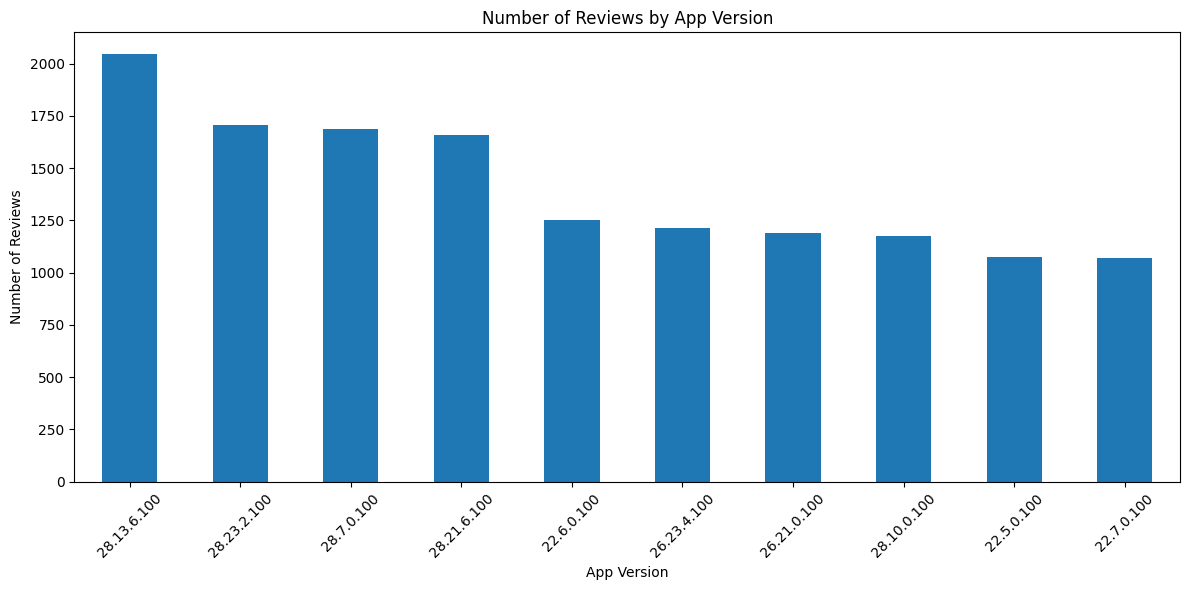

In [22]:
import matplotlib.pyplot as plt

# Number of reviews for each version
app_version_counts = df['appVersion'].value_counts().head(10)

# Plotting a graph
plt.figure(figsize=(12, 6))

app_version_counts.plot(kind='bar')

plt.title('Number of Reviews by App Version')
plt.xlabel('App Version')
plt.ylabel('Number of Reviews')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
import plotly.express as px

app_version_counts = (
    df['appVersion']
    .fillna('Missing')
    .value_counts()
    .head(10)
    .reset_index()
)

app_version_counts.columns = ['appVersion', 'review_count']

fig = px.bar(
    app_version_counts,
    x='appVersion',
    y='review_count',
    title='Top 10 App Versions by Number of Reviews',
    labels={
        'appVersion': 'App Version',
        'review_count': 'Number of Reviews'
    },
    text='review_count'
)

fig.update_layout(
    xaxis_tickangle=-45,
    width=1000,
    height=600
)

fig.show()

In [24]:
import pandas as pd
import plotly.express as px

# Convert the 'at' column to date and time.
df['at'] = pd.to_datetime(df['at'])

# Extract date only
daily_reviews = (
    df['at']
    .dt.date
    .value_counts()
    .sort_index()
    .reset_index()
)

daily_reviews.columns = ['date', 'review_count']

# Plotting a graph
fig = px.line(
    daily_reviews,
    x='date',
    y='review_count',
    title='Number of Reviews per Day',
    labels={
        'date': 'Date',
        'review_count': 'Number of Reviews'
    }
)

fig.show()

In [25]:
import pandas as pd
import plotly.express as px

# Convert the 'at' column to a date
df['at'] = pd.to_datetime(df['at'])

# Creating emotion labels based on scores
df['sentiment'] = df['score'].map({
    1: 'bad',
    2: 'bad',
    3: 'normal',
    4: 'good',
    5: 'good'
})

# Year extraction
df['year'] = df['at'].dt.year

# Counting the number of each type of comment per year
yearly_sentiment = (
    df.groupby(['year', 'sentiment'])
      .size()
      .reset_index(name='review_count')
)

# Plotting a graph
fig = px.bar(
    yearly_sentiment,
    x='year',
    y='review_count',
    color='sentiment',
    barmode='group',
    title='Number of Reviews by Sentiment and Year',
    labels={
        'year': 'Year',
        'review_count': 'Number of Reviews',
        'sentiment': 'Sentiment'
    },
    text='review_count'
)

fig.update_layout(
    width=1000,
    height=600
)

fig.show()

In [26]:
df['word_count'] = df['content'].fillna('').str.split().str.len()

print(df['word_count'].describe())

count    90843.000000
mean        33.557621
std         27.116914
min          0.000000
25%         12.000000
50%         26.000000
75%         49.000000
max        306.000000
Name: word_count, dtype: float64


In [27]:
"""
The `word_count` has been calculated for all 90,843 records.
Each review contains an average of approximately 34 words.
50% of the reviews have 26 words or fewer, while the other 50% have more than 26 words.
The mean is higher than the median, indicating the presence of relatively long reviews that have raised the average.
A large portion of the texts in the dataset are relatively short.
After calculation, at least one review was found to contain no words.

This aligns with our earlier finding that 7 records had empty content.
The longest review contains 306 words.
This EDA provides an initial insight that our texts are not excessively long;
we will need to determine an appropriate `max_length` later during the tokenization stage.
"""

'\nThe `word_count` has been calculated for all 90,843 records.\nEach review contains an average of approximately 34 words.\n50% of the reviews have 26 words or fewer, while the other 50% have more than 26 words.\nThe mean is higher than the median, indicating the presence of relatively long reviews that have raised the average.\nA large portion of the texts in the dataset are relatively short.\nAfter calculation, at least one review was found to contain no words.\n\nThis aligns with our earlier finding that 7 records had empty content.\nThe longest review contains 306 words.\nThis EDA provides an initial insight that our texts are not excessively long;\nwe will need to determine an appropriate `max_length` later during the tokenization stage.\n'

In [28]:
import plotly.express as px

fig = px.histogram(
    df,
    x='word_count',
    nbins=50,
    title='Distribution of Review Length',
    labels={
        'word_count': 'Number of Words',
        'count': 'Number of Reviews'
    }
)

fig.show()

In [29]:
"""
1. The distribution is heavily right-skewed.
Most reviews are clustered on the left side of the chart, meaning they contain few words; the number of reviews decreases as the review length increases.

2. Most reviews are under 100 words.
The chart shows that the bulk of the data falls within the 0 to 100-word range.

3. Very long reviews are rare.
Beyond the 100-word mark, the number of reviews drops sharply, though there are some reviews reaching up to approximately 306 words.

4. This is important for LSTMs.
If we set `max_length` to, say, 306, short reviews would require a large amount of padding. Therefore
, we need to select an appropriate `max_length` that covers most reviews without introducing excessive padding.

However, we are not selecting the `max_length` just yet; this chart is merely part of the EDA.
"""

'\n1. The distribution is heavily right-skewed.\nMost reviews are clustered on the left side of the chart, meaning they contain few words; the number of reviews decreases as the review length increases.\n\n2. Most reviews are under 100 words.\nThe chart shows that the bulk of the data falls within the 0 to 100-word range.\n\n3. Very long reviews are rare.\nBeyond the 100-word mark, the number of reviews drops sharply, though there are some reviews reaching up to approximately 306 words.\n\n4. This is important for LSTMs.\nIf we set `max_length` to, say, 306, short reviews would require a large amount of padding. Therefore\n, we need to select an appropriate `max_length` that covers most reviews without introducing excessive padding.\n\nHowever, we are not selecting the `max_length` just yet; this chart is merely part of the EDA.\n'

In [30]:
# Calculating the percentage of reviews across different ranges

total_reviews = len(df)

ranges = {
    '0 to 10 words': (0, 10),
    '11 to 20 words': (11, 20),
    '21 to 30 words': (21, 30),
    '31 to 50 words': (31, 50),
    '51 to 100 words': (51, 100),
    'More than 100 words': (101, float('inf'))
}

for name, (min_words, max_words) in ranges.items():
    count = ((df['word_count'] >= min_words) &
             (df['word_count'] <= max_words)).sum()

    percentage = (count / total_reviews) * 100

    print(f'{name}: {count:,} Reviews → {percentage:.2f}%')

0 to 10 words: 20,511 Reviews → 22.58%
11 to 20 words: 15,365 Reviews → 16.91%
21 to 30 words: 15,810 Reviews → 17.40%
31 to 50 words: 17,231 Reviews → 18.97%
51 to 100 words: 21,447 Reviews → 23.61%
More than 100 words: 479 Reviews → 0.53%


In [31]:
'''
The largest share of reviews falls within the 51–100 word range (23.61%).
Short reviews (0–10 words) account for a nearly equal proportion (22.58%).
Only 0.53% of reviews exceed 100 words.
Consequently, almost all reviews (99.47%) consist of 100 words or fewer.

This is highly significant for subsequent NLP preprocessing and determining the `max_length` parameter in LSTM models
, as it indicates that there is no need to set an excessively large sequence length.
'''

'\nThe largest share of reviews falls within the 51–100 word range (23.61%).\nShort reviews (0–10 words) account for a nearly equal proportion (22.58%).\nOnly 0.53% of reviews exceed 100 words.\nConsequently, almost all reviews (99.47%) consist of 100 words or fewer.\n\nThis is highly significant for subsequent NLP preprocessing and determining the `max_length` parameter in LSTM models\n, as it indicates that there is no need to set an excessively large sequence length.\n'

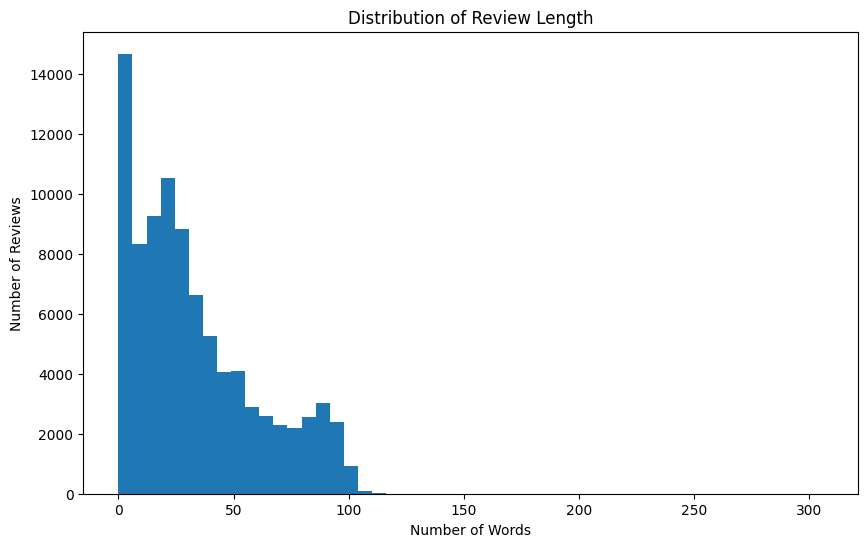

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df['word_count'], bins=50)

plt.title('Distribution of Review Length')
plt.xlabel('Number of Words')
plt.ylabel('Number of Reviews')

plt.show()

In [33]:
# We have a large number of relatively short reviews, and a small number of much longer reviews.

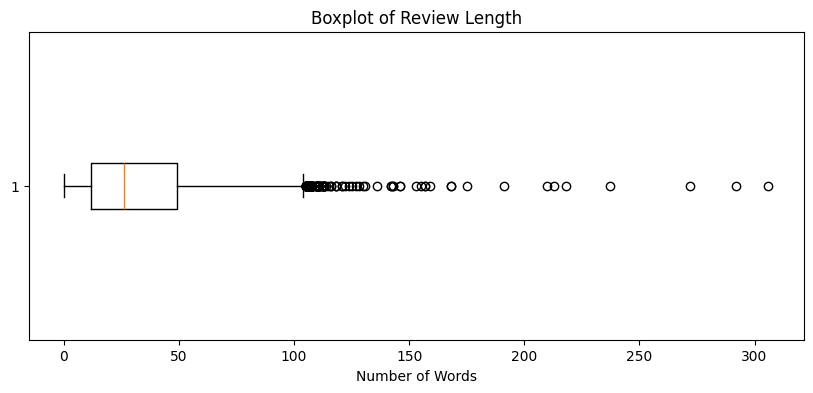

In [34]:
plt.figure(figsize=(10, 4))

plt.boxplot(df['word_count'], vert=False)

plt.title('Boxplot of Review Length')
plt.xlabel('Number of Words')

plt.show()

In [35]:
# boxplot helps us understand where the very long reviews are located.

In [36]:
Q1 = df['word_count'].quantile(0.25)
Q3 = df['word_count'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 12.0
Q3: 49.0
IQR: 37.0
Lower Bound: -43.5
Upper Bound: 104.5


In [37]:
'''
Any review exceeding 104.5 words is considered a statistical outlier.
Since `word_count` cannot be negative:
Lower Bound = -43.5
This is practically irrelevant; therefore, only the Upper Bound matters to us.
'''

'\nAny review exceeding 104.5 words is considered a statistical outlier.\nSince `word_count` cannot be negative:\nLower Bound = -43.5\nThis is practically irrelevant; therefore, only the Upper Bound matters to us.\n'

In [38]:
outliers = df[df['word_count'] > 104.5]

print("Number of Outliers:", len(outliers))
print("Percentage of Outliers:",
      len(outliers) / len(df) * 100)

Number of Outliers: 163
Percentage of Outliers: 0.17943044593419416


In [39]:
print("Maximum word count:", df['word_count'].max())

Maximum word count: 306


In [40]:
'''
Maximum word count = 306
Upper Bound = 104.5
Statistical Outliers = 163
Outlier Percentage ≈ 0.18%
In other words, the longest review in the dataset contains 306 words, yet only 163 reviews exceed the statistical threshold of 104.5.
The fact that a review contains 306 words is not inherently a problem. For sentiment analysis,
 it is generally better not to discard such reviews simply because of their length.
 '''

'\nMaximum word count = 306\nUpper Bound = 104.5\nStatistical Outliers = 163\nOutlier Percentage ≈ 0.18%\nIn other words, the longest review in the dataset contains 306 words, yet only 163 reviews exceed the statistical threshold of 104.5.\nThe fact that a review contains 306 words is not inherently a problem. For sentiment analysis,\n it is generally better not to discard such reviews simply because of their length.\n '

In [41]:
outliers[['content', 'word_count']] \
    .sort_values('word_count', ascending=False) \
    .head(10)

,content,word_count
56727,Had a Terrible propaganda created by Amazon.AE...,306
52269,I have been an Amazon customer for 17 years. I...,292
53914,I have been a loyal Amazon Prime customer for ...,272
48185,I have been a loyal Amazon Prime member for ye...,237
62242,Hearing damage IMDb Freedive First off I wo...,218
49007,"First, I hate the Amazon delivery service. I n...",213
43810,"Generally OK, but the ""My orders"" part is supe...",210
44320,"Before using this app, i was not an amazon pri...",191
59074,The Amazon website pretty much has everything ...,175
44095,"This is perhaps the most well-constructed, sol...",168


In [42]:
"""
From the examples above, it is clear that these are primarily genuine and meaningful reviews, not corrupted data. For instance:

306 words → Long review about Amazon
292 words → A 17-year user's experience with Amazon
272 words → Amazon Prime membership experience
237 words → Review of Amazon Prime
218 words → Long review about IMDb/Freedive
213 words → Criticism of Amazon's delivery service
"""

"\nFrom the examples above, it is clear that these are primarily genuine and meaningful reviews, not corrupted data. For instance:\n\n306 words → Long review about Amazon\n292 words → A 17-year user's experience with Amazon\n272 words → Amazon Prime membership experience\n237 words → Review of Amazon Prime\n218 words → Long review about IMDb/Freedive\n213 words → Criticism of Amazon's delivery service\n"

In [43]:
"""
Now, let’s move on to the EDA section itself. We will carry this out step-by-step,
 and effectively, we won't be removing any data.
 """

"\nNow, let’s move on to the EDA section itself. We will carry this out step-by-step,\n and effectively, we won't be removing any data.\n "

In [44]:
print("Missing values in content:")
print(df['content'].isnull().sum())

Missing values in content:
7


In [45]:
missing_count = df['content'].isnull().sum()
missing_percentage = (missing_count / len(df)) * 100

print(f"Missing Reviews: {missing_count:,}")
print(f"Missing Percentage: {missing_percentage:.2f}%")

Missing Reviews: 7
Missing Percentage: 0.01%


In [46]:
empty_count = (df['content'].fillna('').str.strip() == '').sum()

print(f"Empty Reviews: {empty_count:,}")
print(f"Empty Percentage: {(empty_count / len(df)) * 100:.2f}%")

Empty Reviews: 7
Empty Percentage: 0.01%


In [47]:
"""
In other words, in this dataset, it appears that the seven rows with missing content have also been counted as "empty text,"
 so there is no separate category for empty text.
 """

'\nIn other words, in this dataset, it appears that the seven rows with missing content have also been counted as "empty text,"\n so there is no separate category for empty text.\n '

In [48]:
df[df['content'].isnull()]

,reviewId,userName,content,score,thumbsUpCount,reviewCreatedVersion,at,appVersion,sentiment,year,word_count
2682,72a9d3e5-5d3b-419a-8886-559cfdc5ca15,Jeanette Bellefleur,NaN,4,0,32.10.1.100,2026-06-13 05:02:17,32.10.1.100,good,2026,0
16265,25078450-360e-42f4-a4c3-8523012def46,David Chibitty,NaN,3,0,NaN,2025-06-05 01:35:40,NaN,normal,2025,0
21246,2b2ddcef-3f1d-410b-ac24-9a93e6189fd7,Ailsa Rattray,NaN,1,0,28.23.2.100,2025-02-07 14:30:37,28.23.2.100,bad,2025,0
32481,4e5711ce-dec1-4718-a053-761cc5fbea9b,Martinez leah vlog,NaN,5,0,28.15.0.100,2024-08-13 07:34:34,28.15.0.100,good,2024,0
32704,a887008a-576a-4ca3-accf-2cb4d6b1f68b,Donquel Afonso,NaN,5,0,NaN,2024-08-09 17:08:51,NaN,good,2024,0
39331,33952dff-6094-4807-8db2-47dada5d3d1f,Amir Louis,NaN,1,0,NaN,2024-05-24 19:15:28,NaN,bad,2024,0
39917,3461847b-0371-4533-9620-3f476bbbb9ab,Steeve Roy,NaN,5,0,26.23.0.100,2024-05-18 18:27:00,26.23.0.100,good,2024,0


In [49]:
"""
For text-based sentiment analysis, these 7 rows cannot be used,
as the model is intended to learn sentiment from the review text, and these rows contain no text at all.
Therefore, we can remove these 7 rows during the cleaning stage:
"""

'\nFor text-based sentiment analysis, these 7 rows cannot be used,\nas the model is intended to learn sentiment from the review text, and these rows contain no text at all.\nTherefore, we can remove these 7 rows during the cleaning stage:\n'

In [50]:
df = df.dropna(subset=['content']).copy()

In [51]:
print("Shape after removing missing content:", df.shape)
print("Missing content:", df['content'].isnull().sum())

Shape after removing missing content: (90836, 11)
Missing content: 0


In [52]:
print("Reviews with 1 word:",
      (df['word_count'] == 1).sum())

print("Reviews with 2 words:",
      (df['word_count'] == 2).sum())

print("Reviews with 3 words:",
      (df['word_count'] == 3).sum())

Reviews with 1 word: 3385
Reviews with 2 words: 2949
Reviews with 3 words: 2487


In [53]:
duplicate_count = df['content'].duplicated().sum()

print("Duplicate Reviews:", duplicate_count)
print("Duplicate Percentage:",
      duplicate_count / len(df) * 100)

Duplicate Reviews: 4524
Duplicate Percentage: 4.98040424501299


In [54]:
df[df['content'].duplicated(keep=False)][
    ['content', 'word_count']
].sort_values('content').head(10)

,content,word_count
40153,"""This address is used as your residential addr...",36
40058,"""This address is used as your residential addr...",36
40105,"""This address is used as your residential addr...",36
40068,4/6/21 - Really need to give a dark mode optio...,53
40163,4/6/21 - Really need to give a dark mode optio...,53
40115,4/6/21 - Really need to give a dark mode optio...,53
4521,5 stars,2
21055,5 stars,2
14789,5 stars,2
20148,5 stars,2


In [55]:
"""
We must note here that a duplicate entry does not necessarily imply incorrect data;
multiple users might have written the exact same text. Therefore, we will make a decision later based on the dataset's structure.
"""

"\nWe must note here that a duplicate entry does not necessarily imply incorrect data;\nmultiple users might have written the exact same text. Therefore, we will make a decision later based on the dataset's structure.\n"

In [56]:
"""
However, there is a crucial point here: we should not delete these 4,524 rows just yet.

Why?

The `duplicated()` method only checks whether the `content` value has appeared before.
 Yet, identical text might have been submitted by multiple users—potentially with differing scores or sentiment ratings.

For instance:

User A → "Very good" → score = 5
User B → "Very good" → score = 4
User C → "Very good" → score = 2

If we were to check only the `content`, all of these would be classified as duplicates;
 however, from a data analysis perspective, a more important question arises: are the labels associated with this repeated text consistent?
 """

'\nHowever, there is a crucial point here: we should not delete these 4,524 rows just yet.\n\nWhy?\n\nThe `duplicated()` method only checks whether the `content` value has appeared before.\n Yet, identical text might have been submitted by multiple users—potentially with differing scores or sentiment ratings.\n\nFor instance:\n\nUser A → "Very good" → score = 5\nUser B → "Very good" → score = 4\nUser C → "Very good" → score = 2\n\nIf we were to check only the `content`, all of these would be classified as duplicates;\n however, from a data analysis perspective, a more important question arises: are the labels associated with this repeated text consistent?\n '

In [57]:
duplicate_counts = df['content'].value_counts()

print(duplicate_counts.head(20))

content
good         412
Good         323
Great        216
great        151
love it      125
excellent     94
Excellent     92
awesome       78
nice          73
very good     71
Awesome       63
👍             55
ok            53
Love it       51
Nice          48
Very good     44
good 👍        41
amazing       38
great app     36
I love it     35
Name: count, dtype: int64


In [58]:

"""
An interesting point:

For example:

good → 412
Good → 323

To pandas, these are two different strings because the casing differs.

After cleaning—once we convert all text to lowercase:

good
Good
GOOD

They all become:

good

Consequently, the number of actual duplicates may increase after cleaning.

"""

'\nAn interesting point:\n\nFor example:\n\ngood → 412\nGood → 323\n\nTo pandas, these are two different strings because the casing differs.\n\nAfter cleaning—once we convert all text to lowercase:\n\ngood\nGood\nGOOD\n\nThey all become:\n\ngood\n\nConsequently, the number of actual duplicates may increase after cleaning.\n\n'

In [59]:
repeated_texts = duplicate_counts[duplicate_counts > 1]

print("Number of repeated texts:", len(repeated_texts))

Number of repeated texts: 923


In [60]:
duplicate_df = df[
    df['content'].duplicated(keep=False)
][['content', 'score', 'sentiment']]

duplicate_df.sort_values('content').head(30)

,content,score,sentiment
40153,"""This address is used as your residential addr...",1,bad
40058,"""This address is used as your residential addr...",1,bad
40105,"""This address is used as your residential addr...",1,bad
40068,4/6/21 - Really need to give a dark mode optio...,1,bad
40163,4/6/21 - Really need to give a dark mode optio...,1,bad
40115,4/6/21 - Really need to give a dark mode optio...,1,bad
4521,5 stars,5,good
21055,5 stars,5,good
14789,5 stars,5,good
20148,5 stars,5,good


In [61]:
conflicting_duplicates = (
    duplicate_df
    .groupby('content')['sentiment']
    .nunique()
)

conflicting_duplicates = conflicting_duplicates[
    conflicting_duplicates > 1
]

print("Conflicting duplicate texts:",
      len(conflicting_duplicates))

Conflicting duplicate texts: 133


In [62]:
"""
This result is very important:

Conflicting duplicate texts = 133

This means that out of 923 recurring texts, 133 have at least two different sentiments.

For example, we might have something like this:

content        score    sentiment
----------------------------------
"good"            5       good
"good"            4       good
"good"            1       bad

This means we have a label conflict.

However, we shouldn't delete these 133 cases just yet.

First, we need to see how serious the discrepancies actually are. For instance, it might be:

score = 4 → good
score = 3 → normal

which is an expected difference, or it could be:

score = 5 → good
score = 1 → bad

which is a much more serious contradiction.
"""

'\nThis result is very important:\n\nConflicting duplicate texts = 133\n\nThis means that out of 923 recurring texts, 133 have at least two different sentiments.\n\nFor example, we might have something like this:\n\ncontent        score    sentiment\n----------------------------------\n"good"            5       good\n"good"            4       good\n"good"            1       bad\n\nThis means we have a label conflict.\n\nHowever, we shouldn\'t delete these 133 cases just yet.\n\nFirst, we need to see how serious the discrepancies actually are. For instance, it might be:\n\nscore = 4 → good\nscore = 3 → normal\n\nwhich is an expected difference, or it could be:\n\nscore = 5 → good\nscore = 1 → bad\n\nwhich is a much more serious contradiction.\n'

In [63]:
conflicting_texts = (
    duplicate_df[
        duplicate_df['content'].isin(conflicting_duplicates.index)
    ]
    .sort_values('content')
)

conflicting_texts.head(30)

,content,score,sentiment
27288,A good app,5,good
24350,A good app,2,bad
16197,Adding an extra click to get to your orders is...,3,normal
19971,Adding an extra click to get to your orders is...,1,bad
27658,All,5,good
39114,All,2,bad
33267,Amazing,5,good
13595,Amazing,5,good
23654,Amazing,5,good
34028,Amazing,5,good


In [64]:
conflict_summary = (
    conflicting_texts
    .groupby('content')
    .agg(
        review_count=('content', 'size'),
        unique_scores=('score', 'nunique'),
        unique_sentiments=('sentiment', 'nunique')
    )
    .sort_values('review_count', ascending=False)
)

conflict_summary.head(20)

,review_count,unique_scores,unique_sentiments
content,,,
good,412,5,3
Good,323,5,3
Great,216,4,3
great,151,4,3
love it,125,3,2
nice,73,5,3
very good,71,3,2
👍,55,4,3
ok,53,5,3


In [65]:
"""
An even more important check

Since sentiment is likely derived from the score,
it is worth examining whether the relationship between score and sentiment holds true across the entire dataset:
 """

'\nAn even more important check\n\nSince sentiment is likely derived from the score,\nit is worth examining whether the relationship between score and sentiment holds true across the entire dataset:\n '

In [66]:
pd.crosstab(df['score'], df['sentiment'])

sentiment,bad,good,normal
score,,,
1,41665,0,0
2,9421,0,0
3,0,0,7286
4,0,5811,0
5,0,26653,0


In [67]:
"""
Current Project Status
90,843 Reviews
      ↓
7 Missing content
      ↓
4,524 Duplicate rows
      ↓
923 Repeated unique texts
      ↓
133 Conflicting repeated texts
      ↓
🔎 Investigating the cause of the conflict
"""

'\nCurrent Project Status\n90,843 Reviews\n      ↓\n7 Missing content\n      ↓\n4,524 Duplicate rows\n      ↓\n923 Repeated unique texts\n      ↓\n133 Conflicting repeated texts\n      ↓\n🔎 Investigating the cause of the conflict\n'

In [68]:
conflict_summary.head(20)

,review_count,unique_scores,unique_sentiments
content,,,
good,412,5,3
Good,323,5,3
Great,216,4,3
great,151,4,3
love it,125,3,2
nice,73,5,3
very good,71,3,2
👍,55,4,3
ok,53,5,3


In [69]:
conflict_score_summary = (
    conflicting_texts
    .groupby('content')
    .agg(
        review_count=('content', 'size'),
        min_score=('score', 'min'),
        max_score=('score', 'max'),
        unique_scores=('score', 'nunique')
    )
    .sort_values('review_count', ascending=False)
)

conflict_score_summary.head(20)

,review_count,min_score,max_score,unique_scores
content,,,,
good,412,1,5,5
Good,323,1,5,5
Great,216,1,5,4
great,151,1,5,4
love it,125,3,5,3
nice,73,1,5,5
very good,71,3,5,3
👍,55,1,5,4
ok,53,1,5,5


In [70]:
"""
This output highlighted an important point: these 133 cases are not necessarily data errors;
 rather, short, generic texts—such as "good," "great," and "ok"—have been recorded with varying scores.

For example:

"good"       → score 1 to 5
"Good"       → score 1 to 5
"Great"      → score 1 to 5
"love it"    → score 3 to 5
"ok"         → score 1 to 5

Thus, the same text can appear in the dataset with different ratings.

🔴 However, this presents a serious issue for sentiment analysis.

For instance:

"good"
score = 1 → bad
score = 5 → good

Consequently, if the model considers only the content, there are two different labels for the phrase "good."

This implies the presence of label noise or label ambiguity.
"""

'\nThis output highlighted an important point: these 133 cases are not necessarily data errors;\n rather, short, generic texts—such as "good," "great," and "ok"—have been recorded with varying scores.\n\nFor example:\n\n"good"       → score 1 to 5\n"Good"       → score 1 to 5\n"Great"      → score 1 to 5\n"love it"    → score 3 to 5\n"ok"         → score 1 to 5\n\nThus, the same text can appear in the dataset with different ratings.\n\n🔴 However, this presents a serious issue for sentiment analysis.\n\nFor instance:\n\n"good"\nscore = 1 → bad\nscore = 5 → good\n\nConsequently, if the model considers only the content, there are two different labels for the phrase "good."\n\nThis implies the presence of label noise or label ambiguity.\n'

In [71]:
conflicting_rows = df[
    df['content'].isin(conflicting_duplicates.index)
]

print("Conflicting rows:", len(conflicting_rows))

print("Percentage:",
      len(conflicting_rows) / len(df) * 100)

Conflicting rows: 2318
Percentage: 2.551851688757761


In [72]:
"""
These 2,318 rows do not mean that we have 2,318 corrupted data entries. These rows belong to the same 133 duplicate texts,
where a single text appears with different scores.

For example:

"good" → score 1 → bad
"good" → score 5 → good

Therefore, the main problem is label ambiguity for some texts.
"""

'\nThese 2,318 rows do not mean that we have 2,318 corrupted data entries. These rows belong to the same 133 duplicate texts,\nwhere a single text appears with different scores.\n\nFor example:\n\n"good" → score 1 → bad\n"good" → score 5 → good\n\nTherefore, the main problem is label ambiguity for some texts.\n'

In [73]:
severe_conflicts = (
    conflicting_rows
    .groupby('content')['score']
    .agg(['min', 'max'])
)

severe_conflicts = severe_conflicts[
    (severe_conflicts['min'] <= 2) &
    (severe_conflicts['max'] >= 4)
]

print("Severe conflicting texts:", len(severe_conflicts))

Severe conflicting texts: 75


In [74]:
"""
Excellent. We have now reached an important conclusion:

Conflicting unique texts = 133
Severe conflicting texts = 75

This means that out of the 133 unique conflicting texts, 75 truly fall between the "bad" and "good" categories—for instance,
an identical text has been recorded with scores of both 1 and 5.
"""

'\nExcellent. We have now reached an important conclusion:\n\nConflicting unique texts = 133\nSevere conflicting texts = 75\n\nThis means that out of the 133 unique conflicting texts, 75 truly fall between the "bad" and "good" categories—for instance,\nan identical text has been recorded with scores of both 1 and 5.\n'

In [75]:
"""
Duplicate Status
    Item	                 Count

Duplicate rows	           4,524
Repeated unique texts	      923
Conflicting unique texts	  133
Severe conflicts	           75

Therefore, the core issue concerns only 75 unique texts, rather than treating all 4,524 rows as problematic.
"""

'\nDuplicate Status\n    Item\t                 Count\n\nDuplicate rows\t           4,524\nRepeated unique texts\t      923\nConflicting unique texts\t  133\nSevere conflicts\t           75\n\nTherefore, the core issue concerns only 75 unique texts, rather than treating all 4,524 rows as problematic.\n'

In [76]:
"""
Should we remove the 75 texts?

For my Sentiment Analysis project, I suggest we don't remove them for now.

A key reason:

Texts such as:

good
Great
nice
ok
👍

...might actually be associated with different ratings. For instance, "ok" could be rated as 2 stars by one user and 4 stars by another.

However, this creates a significant problem for the model:

"good"
   ↓
bad ❌
good ✅

The model cannot determine the correct label based on the text alone.
"""

'\nShould we remove the 75 texts?\n\nFor my Sentiment Analysis project, I suggest we don\'t remove them for now.\n\nA key reason:\n\nTexts such as:\n\ngood\nGreat\nnice\nok\n👍\n\n...might actually be associated with different ratings. For instance, "ok" could be rated as 2 stars by one user and 4 stars by another.\n\nHowever, this creates a significant problem for the model:\n\n"good"\n   ↓\nbad ❌\ngood ✅\n\nThe model cannot determine the correct label based on the text alone.\n'

In [77]:
"""

The best decision for our project

Instead of blindly removing them, we identify these instances as label noise or ambiguous samples.

In the EDA report, I can write:

A small portion of the dataset consists of duplicate review texts with conflicting sentiment labels.
These samples were identified as potential instances of label noise and were not automatically removed at this stage.

This approach is preferable from a data science perspective,
as the decision to remove data is based on an actual review rather than simply relying on `duplicated()`.

If our goal is to create a clean dataset for training an LSTM, we could ultimately remove these 75 items; however,
 it is better not to remove them just yet.

The reason is that we haven't performed text cleaning yet. After converting to lowercase and normalizing the text,
 more items might turn out to be actual duplicates.

"""

"\n\nThe best decision for our project\n\nInstead of blindly removing them, we identify these instances as label noise or ambiguous samples.\n\nIn the EDA report, I can write:\n\nA small portion of the dataset consists of duplicate review texts with conflicting sentiment labels.\nThese samples were identified as potential instances of label noise and were not automatically removed at this stage.\n\nThis approach is preferable from a data science perspective,\nas the decision to remove data is based on an actual review rather than simply relying on `duplicated()`.\n\nIf our goal is to create a clean dataset for training an LSTM, we could ultimately remove these 75 items; however,\n it is better not to remove them just yet.\n\nThe reason is that we haven't performed text cleaning yet. After converting to lowercase and normalizing the text,\n more items might turn out to be actual duplicates.\n\n"

In [78]:
"""

Now, let's move on to actual content cleaning.

So far, we have performed statistical EDA. The next step is far more critical:

Assessing text quality

We want to identify what the reviews contain:

HTML tags
URLs
Email addresses
Special characters
Numbers
Emojis
Extra spaces
Uppercase letters

"""

"\n\nNow, let's move on to actual content cleaning.\n\nSo far, we have performed statistical EDA. The next step is far more critical:\n\nAssessing text quality\n\nWe want to identify what the reviews contain:\n\nHTML tags\nURLs\nEmail addresses\nSpecial characters\nNumbers\nEmojis\nExtra spaces\nUppercase letters\n\n"

In [79]:
# First of all, let's check the URL.

In [80]:
import re

url_pattern = r'https?://\S+|www\.\S+'

url_count = df['content'].fillna('').str.contains(
    url_pattern,
    regex=True
).sum()

print("Reviews containing URLs:", url_count)
print("Percentage:",
      url_count / len(df) * 100)

Reviews containing URLs: 0
Percentage: 0.0


In [81]:
# Since there are no URLs in our dataset, we can skip the URL removal or replacement step; there is no need to execute code to remove URLs.

In [82]:
# Next step: Reviewing HTML

In [83]:
html_pattern = r'<[^>]+>'

html_count = df['content'].fillna('').str.contains(
    html_pattern,
    regex=True
).sum()

print("Reviews containing HTML tags:", html_count)
print("Percentage:", round(html_count / len(df) * 100, 2), "%")

Reviews containing HTML tags: 4
Percentage: 0.0 %


In [84]:
"""
Four reviews contain HTML tags.
When rounded to two decimal places, the percentage appears as 0.0%; in reality, it represents approximately 0.0044% of the total data.
Therefore, HTML is virtually absent from our dataset.

Now, let’s examine these four examples to confirm that they are indeed HTML tags:
"""

'\nFour reviews contain HTML tags.\nWhen rounded to two decimal places, the percentage appears as 0.0%; in reality, it represents approximately 0.0044% of the total data.\nTherefore, HTML is virtually absent from our dataset.\n\nNow, let’s examine these four examples to confirm that they are indeed HTML tags:\n'

In [85]:
html_reviews = df[
    df['content'].fillna('').str.contains(
        html_pattern,
        regex=True
    )
]

print(html_reviews['content'].to_string(index=False))

😡😡😡😡😡😡😡😡😡😡😡🤬🤬🤬🤬🤬🤬🤬🤬🤬🤬😠😠😠😠😠😠😠😾😾😾😾😾😾👎ヽ(　`Д´)ﾉ<(｀^...
"Created by AI' <-- OBVIOUSLY! 'We don't need n...
           ||<["error 404 world"] ["boundless"]>||
There is no way to easily watch, save, or wishl...


In [86]:
"""
This output shows that these items are not actually HTML—or at least, most of them are just plain text.

For example:

😡😡😡... → Emoji
👎 → Emoji
ヽ(　Д´)ﾉ` → Emoticon / Text-based emoticon
"Created by AI' <-- OBVIOUSLY!" → Plain text + punctuation marks
["error 404 world"] ["boundless"] → Brackets and special characters

So, we arrive at an important point here:

🔴 We should not remove emojis.

For sentiment analysis, emojis contain highly valuable emotional information.

"""

'\nThis output shows that these items are not actually HTML—or at least, most of them are just plain text.\n\nFor example:\n\n😡😡😡... → Emoji\n👎 → Emoji\nヽ(\u3000Д´)ﾉ` → Emoticon / Text-based emoticon\n"Created by AI\' <-- OBVIOUSLY!" → Plain text + punctuation marks\n["error 404 world"] ["boundless"] → Brackets and special characters\n\nSo, we arrive at an important point here:\n\n🔴 We should not remove emojis.\n\nFor sentiment analysis, emojis contain highly valuable emotional information.\n\n'

In [87]:
emoji_pattern = (
    r'['
    r'\U0001F300-\U0001F5FF'
    r'\U0001F600-\U0001F64F'
    r'\U0001F680-\U0001F6FF'
    r'\U0001F700-\U0001F77F'
    r'\U0001F900-\U0001F9FF'
    r'\U0001FA00-\U0001FAFF'
    r'\U00002700-\U000027BF'
    r'\U0001F1E0-\U0001F1FF'
    r']'
)

emoji_count = df['content'].fillna('').str.contains(
    emoji_pattern,
    regex=True
).sum()

print("Reviews containing emojis:", emoji_count)
print("Percentage:", round(emoji_count / len(df) * 100, 2), "%")

Reviews containing emojis: 5474
Percentage: 6.03 %


In [88]:
"""
Number of reviews containing emojis: 5,474
Percentage: 6.03%
This means approximately one in every 17 reviews contains an emoji.

Therefore, we will not remove the emojis, as they convey important information—such as anger, satisfaction, sadness,
and approval—for sentiment analysis.
"""

'\nNumber of reviews containing emojis: 5,474\nPercentage: 6.03%\nThis means approximately one in every 17 reviews contains an emoji.\n\nTherefore, we will not remove the emojis, as they convey important information—such as anger, satisfaction, sadness,\nand approval—for sentiment analysis.\n'

In [89]:
"""
Now, we want to see how many reviews contain punctuation marks such as:

!  ?  .  ,  :  ;  '  "  ( )  -  ...
"""

'\nNow, we want to see how many reviews contain punctuation marks such as:\n\n!  ?  .  ,  :  ;  \'  "  ( )  -  ...\n'

In [90]:
import string

punctuation_pattern = '[' + re.escape(string.punctuation) + ']'

punctuation_count = df['content'].fillna('').str.contains(
    punctuation_pattern,
    regex=True
).sum()

print("Reviews containing punctuation:", punctuation_count)
print(
    "Percentage:",
    round(punctuation_count / len(df) * 100, 2),
    "%"
)

Reviews containing punctuation: 76079
Percentage: 83.75 %


In [91]:
"""
 This result is entirely expected:

76,079 reviews contain punctuation marks.
That is 83.75% of all reviews.
So, the vast majority of texts in the dataset contain punctuation.

However, we face an important decision here: we should not remove all punctuation marks.
"""

'\n This result is entirely expected:\n\n76,079 reviews contain punctuation marks.\nThat is 83.75% of all reviews.\nSo, the vast majority of texts in the dataset contain punctuation.\n\nHowever, we face an important decision here: we should not remove all punctuation marks.\n'

In [92]:
"""
Let's adopt this policy for now:

     Item	                    Decision

  ! and ?                      	Keep

   Emoji                      	Keep

  . , : ;                 	Likely remove

    '	                      Keep for now; important for *don't*, *can't*

  ( ) [ ]                   Likely remove

     -                    	Review later

   HTML	                    Remove tags

    URL                   	Not needed

Uppercase letters         	Convert to lowercase

Extra spaces              	Remove

"""

"\nLet's adopt this policy for now:\n\n     Item\t                    Decision\n\n  ! and ?                      \tKeep\n\n   Emoji                      \tKeep\n\n  . , : ;                 \tLikely remove\n\n    '\t                      Keep for now; important for *don't*, *can't*\n\n  ( ) [ ]                   Likely remove\n\n     -                    \tReview later\n\n   HTML\t                    Remove tags\n\n    URL                   \tNot needed\n\nUppercase letters         \tConvert to lowercase\n\nExtra spaces              \tRemove\n\n"

In [93]:
# How many reviews contain a number?

In [94]:
number_pattern = r'\d+'

number_count = df['content'].fillna('').str.contains(
    number_pattern,
    regex=True
).sum()

print("Reviews containing numbers:", number_count)
print(
    "Percentage:",
    round(number_count / len(df) * 100, 2),
    "%"
)

Reviews containing numbers: 19390
Percentage: 21.35 %


In [95]:
"""
Very well. We have an interesting result here as well:

19,390 reviews contain numbers.
That represents 21.35% of the total data.
So, approximately one in every five reviews includes a number.

Therefore, we won't remove the numbers for now.

"""

"\nVery well. We have an interesting result here as well:\n\n19,390 reviews contain numbers.\nThat represents 21.35% of the total data.\nSo, approximately one in every five reviews includes a number.\n\nTherefore, we won't remove the numbers for now.\n\n"

In [96]:
# Now, we want to see how many reviews contain uppercase English letters.

In [97]:
uppercase_pattern = r'[A-Z]'

uppercase_count = df['content'].fillna('').str.contains(
    uppercase_pattern,
    regex=True
).sum()

print("Reviews containing uppercase letters:", uppercase_count)
print(
    "Percentage:",
    round(uppercase_count / len(df) * 100, 2),
    "%"
)

Reviews containing uppercase letters: 79992
Percentage: 88.06 %


In [98]:
"""
 This result shows that uppercase letters appear in 88.06% of the reviews; therefore,
 converting the text to lowercase will be one of the most important parts of our normalization process.

Why do we do this?

For instance, under the current model, these two texts might be treated as distinct tokens:

Good

and

good

...even though they are semantically almost identical.

Therefore, during the normalization stage, we typically convert the entire text to lowercase:
This reduces the size of the vocabulary and makes it more suitable for an LSTM.
"""

'\n This result shows that uppercase letters appear in 88.06% of the reviews; therefore,\n converting the text to lowercase will be one of the most important parts of our normalization process.\n\nWhy do we do this?\n\nFor instance, under the current model, these two texts might be treated as distinct tokens:\n\nGood\n\nand\n\ngood\n\n...even though they are semantically almost identical.\n\nTherefore, during the normalization stage, we typically convert the entire text to lowercase:\nThis reduces the size of the vocabulary and makes it more suitable for an LSTM.\n'

In [99]:
"""

Current EDA Results:

Item	          Count	        Percentage            	Decision

URL	              0             	0%	             No action needed

HTML	            4	           ~0.004%              	Remove tags

Emoji	          5,474	          6.03%	                   Keep

Punctuation	    76,079         	83.75%          	Remove selectively

Numbers	        19,390	       21.35%	            Keep for now

Uppercase     	79,992	        88.06%          	Convert to lowercase

"""

'\n\nCurrent EDA Results:\n\nItem\t          Count\t        Percentage            \tDecision\n\nURL\t              0             \t0%\t             No action needed\n\nHTML\t            4\t           ~0.004%              \tRemove tags\n\nEmoji\t          5,474\t          6.03%\t                   Keep\n\nPunctuation\t    76,079         \t83.75%          \tRemove selectively\n\nNumbers\t        19,390\t       21.35%\t            Keep for now\n\nUppercase     \t79,992\t        88.06%          \tConvert to lowercase\n\n'

In [100]:
# Next step: Check for non-English characters.

In [101]:
non_ascii_pattern = r'[^\x00-\x7F]'

non_ascii_count = df['content'].fillna('').str.contains(
    non_ascii_pattern,
    regex=True
).sum()

print("Reviews containing non-ASCII characters:", non_ascii_count)
print(
    "Percentage:",
    round(non_ascii_count / len(df) * 100, 2),
    "%"
)

Reviews containing non-ASCII characters: 7409
Percentage: 8.16 %


In [102]:
non_ascii_reviews = df[
    df['content'].fillna('').str.contains(
        non_ascii_pattern,
        regex=True
    )
]

print(
    non_ascii_reviews['content']
    .head(30)
    .to_string(index=False)
)

                                        fabulous 😍
you keep showing me the same blue rays that I a...
Amazon Shopping is my go to store for online sh...
I ordered some Pokémon packs and guess what?The...
                                             ممتاز
  I'm just playing Amazon, you know I love you! 💝💯
​I am writing this comment to raise an urgent a...
mauvaise expérience client. beaucoup de produit...
Love the service and all, but super laggy of an...
⭐⭐⭐⭐⭐ I’m very happy with this purchase. The pr...
                                   lovely apps ❤️😘
So you completely remove the app from Samsung T...
                  this very good and useful app ☺️
What the heck did y'all do to the list page?! I...
No me dejo hacer pagos de un pedido, por supues...
                       very cool stuff ,thank you😎
                         Easy and always on time 😜
               my experience been really good 👍👍😊😊
So easy and convenient to use the app and with ...
the app used to be great but re

In [103]:
# Checking for non-English words/characters (excluding emojis)

In [104]:
non_ascii_no_emoji = df[
    df['content'].fillna('').str.contains(
        non_ascii_pattern,
        regex=True
    )
    &
    ~df['content'].fillna('').str.contains(
        emoji_pattern,
        regex=True
    )
]

print(
    "Non-ASCII reviews without emojis:",
    len(non_ascii_no_emoji)
)

print(
    "Percentage:",
    round(len(non_ascii_no_emoji) / len(df) * 100, 2),
    "%"
)

Non-ASCII reviews without emojis: 1935
Percentage: 2.13 %


In [105]:
"""
Final Results of the Non-ASCII Analysis

Out of the entire dataset:

7,409 reviews contained Non-ASCII characters (8.16%).
Of these, 5,474 reviews contained emojis.
1,935 reviews contained Non-ASCII characters but no emojis (2.13%).

The samples you previously sent showed that these 1,935 cases include languages ​​such as Arabic, French, and Spanish.

Key Decision

Since our project involves sentiment analysis on Amazon reviews and the majority of the text is in English, I suggest:

We do not remove these 1,935 reviews for the time being.

The reason is that removing non-English content could result in discarding valuable real-world data; furthermore,
 we do not yet know exactly which languages ​​are present or the number of samples for each.

However, there is a more important point: if our LSTM model is intended to be trained solely on English text,
 we should later examine what proportion of the training data these 1,935 reviews represent and determine whether removing them is logical.

 """

'\nFinal Results of the Non-ASCII Analysis\n\nOut of the entire dataset:\n\n7,409 reviews contained Non-ASCII characters (8.16%).\nOf these, 5,474 reviews contained emojis.\n1,935 reviews contained Non-ASCII characters but no emojis (2.13%).\n\nThe samples you previously sent showed that these 1,935 cases include languages \u200b\u200bsuch as Arabic, French, and Spanish.\n\nKey Decision\n\nSince our project involves sentiment analysis on Amazon reviews and the majority of the text is in English, I suggest:\n\nWe do not remove these 1,935 reviews for the time being.\n\nThe reason is that removing non-English content could result in discarding valuable real-world data; furthermore,\n we do not yet know exactly which languages \u200b\u200bare present or the number of samples for each.\n\nHowever, there is a more important point: if our LSTM model is intended to be trained solely on English text,\n we should later examine what proportion of the training data these 1,935 reviews represent a

In [106]:
"""

So far, we have examined these points:

   Missing content
       ↓
   Word Count
       ↓
   Outliers
       ↓
   Duplicates
       ↓
Label Conflicts
       ↓
     URLs
       ↓
     HTML
       ↓
     Emoji
       ↓
   Punctuation
       ↓
    Numbers
       ↓
   Uppercase
       ↓
   Non-ASCII

   """

'\n\nSo far, we have examined these points:\n\n   Missing content\n       ↓\n   Word Count\n       ↓\n   Outliers\n       ↓\n   Duplicates\n       ↓\nLabel Conflicts\n       ↓\n     URLs\n       ↓\n     HTML\n       ↓\n     Emoji\n       ↓\n   Punctuation\n       ↓\n    Numbers\n       ↓\n   Uppercase\n       ↓\n   Non-ASCII\n\n   '

In [107]:
"""
Analyzing Sentiment Distribution

Since we ultimately want to train an LSTM to predict sentiment, we need to check whether the classes are balanced.
"""

'\nAnalyzing Sentiment Distribution\n\nSince we ultimately want to train an LSTM to predict sentiment, we need to check whether the classes are balanced.\n'

In [108]:
print(df['sentiment'].value_counts())

print("\nPercentage:")
print(
    round(
        df['sentiment'].value_counts(normalize=True) * 100,
        2
    )
)

sentiment
bad       51086
good      32464
normal     7286
Name: count, dtype: int64

Percentage:
sentiment
bad       56.24
good      35.74
normal     8.02
Name: proportion, dtype: float64


In [109]:
"""

Alright. We’ve arrived at a crucial point regarding the LSTM model: our dataset is imbalanced.

Specifically, the "normal" class accounts for only about 8% of the data, whereas the "bad" class makes up more than half of the dataset.

Is this a problem?

Yes, but it is manageable.

If we train the LSTM directly, the model might become biased toward the "bad" class;
for instance, if it simply predicted "bad" every time, it would achieve an accuracy of around 56% on this dataset alone.

Therefore, we won't rely solely on accuracy. We will also examine the following metrics:

Precision
Recall
F1-score
Confusion Matrix

The Recall and F1-score for the "normal" class are particularly important to us.
"""

'\n\nAlright. We’ve arrived at a crucial point regarding the LSTM model: our dataset is imbalanced.\n\nSpecifically, the "normal" class accounts for only about 8% of the data, whereas the "bad" class makes up more than half of the dataset.\n\nIs this a problem?\n\nYes, but it is manageable.\n\nIf we train the LSTM directly, the model might become biased toward the "bad" class;\nfor instance, if it simply predicted "bad" every time, it would achieve an accuracy of around 56% on this dataset alone.\n\nTherefore, we won\'t rely solely on accuracy. We will also examine the following metrics:\n\nPrecision\nRecall\nF1-score\nConfusion Matrix\n\nThe Recall and F1-score for the "normal" class are particularly important to us.\n'

In [110]:
"""
Now, let's get into the actual cleaning process.

Based on our analysis, we are adopting the following policy for the content:

Remove:
HTML tags
Extra whitespace
Convert:
Uppercase letters → lowercase
Retain:
Emojis
Numbers
Words
Non-English languages
Punctuation: ! and ? (for now)
Apostrophes in words like "don't" and "can't"
Leave as-is (for now):
75 texts with label conflicts
Duplicates
Word-count outliers

"""

'\nNow, let\'s get into the actual cleaning process.\n\nBased on our analysis, we are adopting the following policy for the content:\n\nRemove:\nHTML tags\nExtra whitespace\nConvert:\nUppercase letters → lowercase\nRetain:\nEmojis\nNumbers\nWords\nNon-English languages\nPunctuation: ! and ? (for now)\nApostrophes in words like "don\'t" and "can\'t"\nLeave as-is (for now):\n75 texts with label conflicts\nDuplicates\nWord-count outliers\n\n'

In [111]:
"""
Let's perform the initial cleaning.

For now, let's just handle HTML, extra whitespace, and lowercase conversion:

"""

"\nLet's perform the initial cleaning.\n\nFor now, let's just handle HTML, extra whitespace, and lowercase conversion:\n\n"

In [112]:
def basic_clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Convert uppercase letters to lowercase
    text = text.lower()

    # Removing extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

In [113]:
df['content_clean'] = df['content'].apply(basic_clean_text)

In [114]:
comparison = df[['content', 'content_clean']].head(20)

print(comparison.to_string(index=False))

                                                                                                                                                                                                                                                                                                                                                                        content                                                                                                                                                                                                                                                                                                                                                                   content_clean
                                                                                                                I'm having a serious issue where I can't stop the prime membership. I mistakenly hit archive without cancelling the membership and now I have an issue. 

In [115]:
#Let's examine which symbols have been used the most.

#This code calculates the frequency of each symbol across all reviews:

In [116]:
from collections import Counter
import string

all_punctuation = Counter()

for text in df['content_clean'].fillna(''):
    all_punctuation.update(
        char for char in text
        if char in string.punctuation
    )

for char, count in all_punctuation.most_common():
    print(repr(char), ":", count)

'.' : 212102
"'" : 78034
',' : 76029
'!' : 36807
'"' : 12567
'?' : 11281
'-' : 7700
'/' : 4382
')' : 4298
'(' : 4150
'$' : 3265
'&' : 3113
':' : 2362
'*' : 1381
'%' : 1079
';' : 785
'+' : 774
'#' : 411
'@' : 145
'_' : 137
'=' : 108
'|' : 81
'>' : 70
'~' : 61
'[' : 58
']' : 58
'\\' : 35
'^' : 21
'<' : 14
'}' : 10
'{' : 7
'`' : 4


In [117]:
"""
Symbol Analysis

Symbol      	 Count	      Decision

  .	          212,102     	Remove

  '	          78,034      	Keep

  ,         	76,029      	Remove

  !	          36,807      	Keep

  "	          12,567	      Remove

  ?         	11,281      	Keep

  -         	7,700       	Remove

  /	          4,382   	    Remove

 ( )      	  ~8,448	      Remove

  $	          3,265	        Remove

  &	          3,113        	Remove

  :   	      2,362   	    Remove

  *         	1,381	        Remove

  %	          1,079       	Remove

  ;	          785         	Remove

 Others     	Very few	    Remove

"""

'\nSymbol Analysis\n\nSymbol      \t Count\t      Decision\n\n  .\t          212,102     \tRemove\n\n  \'\t          78,034      \tKeep\n\n  ,         \t76,029      \tRemove\n\n  !\t          36,807      \tKeep\n\n  "\t          12,567\t      Remove\n\n  ?         \t11,281      \tKeep\n\n  -         \t7,700       \tRemove\n\n  /\t          4,382   \t    Remove\n\n ( )      \t  ~8,448\t      Remove\n\n  $\t          3,265\t        Remove\n\n  &\t          3,113        \tRemove\n\n  :   \t      2,362   \t    Remove\n\n  *         \t1,381\t        Remove\n\n  %\t          1,079       \tRemove\n\n  ;\t          785         \tRemove\n\n Others     \tVery few\t    Remove\n\n'

In [118]:
"""
Why do we keep the apostrophe?

Because in words like:

don't
can't
isn't
it's
I've

the apostrophe is part of the word's structure.

For example:

don't

is better than:

dont

Why do we keep ! and ??

For example:

This app is amazing!!!

and:

Why is this app so bad???

These symbols can be useful for sentiment analysis.

"""

"\nWhy do we keep the apostrophe?\n\nBecause in words like:\n\ndon't\ncan't\nisn't\nit's\nI've\n\nthe apostrophe is part of the word's structure.\n\nFor example:\n\ndon't\n\nis better than:\n\ndont\n\nWhy do we keep ! and ??\n\nFor example:\n\nThis app is amazing!!!\n\nand:\n\nWhy is this app so bad???\n\nThese symbols can be useful for sentiment analysis.\n\n"

In [119]:
"""
Now, perform the cleaning.

An important point: Since we already have the `content_clean` column, it is better to use that one and leave the original `content` text untouched.

The code below:

removes unnecessary punctuation
preserves `'`
preserves `!` and `?`
preserves emojis
preserves numbers
normalizes extra whitespace

"""

"\nNow, perform the cleaning.\n\nAn important point: Since we already have the `content_clean` column, it is better to use that one and leave the original `content` text untouched.\n\nThe code below:\n\nremoves unnecessary punctuation\npreserves `'`\npreserves `!` and `?`\npreserves emojis\npreserves numbers\nnormalizes extra whitespace\n\n"

In [120]:
def clean_punctuation(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Removing unnecessary punctuation
    text = re.sub(
        r'[.,\";\-/:$&()*+%=#@_<>|\[\]\\^{}~`]',
        ' ',
        text
    )

    # More than one ! in a row → one !
    text = re.sub(r'!+', '!', text)

    # More than one ? in a row → one ?
    text = re.sub(r'\?+', '?', text)

    # Fixing the spacing before ! and ?
    text = re.sub(r'\s+([!?])', r'\1', text)

    # Adding a space after ! and ?
    text = re.sub(r'([!?])(?=[A-Za-z])', r'\1 ', text)

    # Removing extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

In [121]:
df['content_clean'] = df['content_clean'].apply(clean_punctuation)

In [122]:
comparison = df[['content', 'content_clean']].head(30)

print(comparison.to_string(index=False))

                                                                                                                                                                                                                                                                                                                                                                                                                                                                   content                                                                                                                                                                                                                                                                                                                                                                                                                                              content_clean
                                                                                                  

In [123]:
# Before moving on to tokenization, we need to see what impact cleaning has had on duplicates.

In [124]:
duplicate_clean_count = df['content_clean'].duplicated().sum()

print("Duplicate reviews after cleaning:", duplicate_clean_count)

print(
    "Percentage:",
    round(
        duplicate_clean_count / len(df) * 100,
        2
    ),
    "%"
)

Duplicate reviews after cleaning: 5505
Percentage: 6.06 %


In [125]:
repeated_clean = (
    df['content_clean']
    .value_counts()
)

repeated_clean = repeated_clean[
    repeated_clean > 1
]

print(
    "Number of repeated unique cleaned texts:",
    len(repeated_clean)
)

print("\nTop 20:")
print(repeated_clean.head(20))

Number of repeated unique cleaned texts: 1022

Top 20:
content_clean
good             752
great            390
excellent        196
love it          191
awesome          146
nice             125
very good        122
ok                82
great app         80
love amazon       75
amazing           70
good app          62
good 👍            62
👍                 55
great service     51
easy to use       49
i love amazon     49
no dark mode      45
i love it         44
bad               40
Name: count, dtype: int64


In [126]:
clean_conflicts = (
    df.groupby('content_clean')['sentiment']
      .nunique()
)

conflicting_clean_texts = clean_conflicts[
    clean_conflicts > 1
]

print(
    "Conflicting cleaned texts:",
    len(conflicting_clean_texts)
)

Conflicting cleaned texts: 139


In [127]:
"""
These results indicate that the cleaning process performed exactly as expected,
 allowing us to proceed to the crucial stage of checking for label inconsistencies.

1. The number of duplicates increased from 4,524 to 5,505.

Before cleaning:

Duplicates: 4,524
Percentage: 4.98%

After cleaning:

Duplicates: 5,505
Percentage: 6.06%

This increase is entirely natural, as the cleaning process transformed previously distinct text entries into identical ones.

For example:

Good
good!
GOOD.
good!!!

All of these are converted to:

good

Consequently, they are now treated as a single `content_clean` entry.
"""

'\nThese results indicate that the cleaning process performed exactly as expected,\n allowing us to proceed to the crucial stage of checking for label inconsistencies.\n\n1. The number of duplicates increased from 4,524 to 5,505.\n\nBefore cleaning:\n\nDuplicates: 4,524\nPercentage: 4.98%\n\nAfter cleaning:\n\nDuplicates: 5,505\nPercentage: 6.06%\n\nThis increase is entirely natural, as the cleaning process transformed previously distinct text entries into identical ones.\n\nFor example:\n\nGood\ngood!\nGOOD.\ngood!!!\n\nAll of these are converted to:\n\ngood\n\nConsequently, they are now treated as a single `content_clean` entry.\n'

In [128]:
"""

The number of conflicting texts has risen from 133 to 139.

This is our most significant finding so far:

Conflicting cleaned texts: 139

This means we have 139 unique, cleaned texts that appear in the dataset with more than one sentiment label.

For instance, it is possible that:

content_clean = good

In some rows:

bad

And in other rows:

good

This creates a problem for the LSTM model, as the model only sees the text itself and cannot determine
 why the exact same text is labeled "bad" in one instance and "good" in another.

 """

'\n\nThe number of conflicting texts has risen from 133 to 139.\n\nThis is our most significant finding so far:\n\nConflicting cleaned texts: 139\n\nThis means we have 139 unique, cleaned texts that appear in the dataset with more than one sentiment label.\n\nFor instance, it is possible that:\n\ncontent_clean = good\n\nIn some rows:\n\nbad\n\nAnd in other rows:\n\ngood\n\nThis creates a problem for the LSTM model, as the model only sees the text itself and cannot determine\n why the exact same text is labeled "bad" in one instance and "good" in another.\n\n '

In [129]:
conflict_details = (
    df[df['content_clean'].isin(conflicting_clean_texts.index)]
    .groupby('content_clean')
    .agg(
        count=('content_clean', 'size'),
        unique_scores=('score', 'nunique'),
        min_score=('score', 'min'),
        max_score=('score', 'max'),
        sentiments=('sentiment', lambda x: ', '.join(sorted(x.unique())))
    )
    .sort_values('count', ascending=False)
)

print(conflict_details.head(30))

                   count  unique_scores  min_score  max_score  \
content_clean                                                   
good                 752              5          1          5   
great                390              4          1          5   
love it              191              3          3          5   
nice                 125              5          1          5   
very good            122              3          3          5   
ok                    82              5          1          5   
great app             80              3          3          5   
love amazon           75              3          3          5   
amazing               70              4          1          5   
good app              62              3          2          5   
good 👍                62              3          3          5   
👍                     55              4          1          5   
easy to use           49              3          3          5   
no dark mode          45 

In [130]:
"""
For instance, the label "OK" appears across 82 rows with varying scores ranging from 1 to 5; this is a stark contradiction.

So, what should we remove?

I suggest removing only those entries that are truly ambiguous—meaning the exact
same text has received both highly negative and highly positive scores.
"""

'\nFor instance, the label "OK" appears across 82 rows with varying scores ranging from 1 to 5; this is a stark contradiction.\n\nSo, what should we remove?\n\nI suggest removing only those entries that are truly ambiguous—meaning the exact\nsame text has received both highly negative and highly positive scores.\n'

In [131]:
"""
For example:

Text	         Min	       Max	    Decision

good	          1	          5	     ❌ Remove

great	          1	          5	     ❌ Remove

amazing	        1	          5	     ❌ Remove

good app	      2	          5	     ❌ Remove

good 👍       	3	          5	     ✅ Keep

easy to use	    3	          5	     ✅ Keep

love amazon	    3	          5	     ✅ Keep

no dark mode	  1	          4	     ❌ Remove

bad	            1	          5	     ❌ Remove

very bad	      1	          5      ❌ Remove

wow	            3         	5	     ✅ Keep

"""

'\nFor example:\n\nText\t         Min\t       Max\t    Decision\n\ngood\t          1\t          5\t     ❌ Remove\n\ngreat\t          1\t          5\t     ❌ Remove\n\namazing\t        1\t          5\t     ❌ Remove\n\ngood app\t      2\t          5\t     ❌ Remove\n\ngood 👍       \t3\t          5\t     ✅ Keep\n\neasy to use\t    3\t          5\t     ✅ Keep\n\nlove amazon\t    3\t          5\t     ✅ Keep\n\nno dark mode\t  1\t          4\t     ❌ Remove\n\nbad\t            1\t          5\t     ❌ Remove\n\nvery bad\t      1\t          5      ❌ Remove\n\nwow\t            3         \t5\t     ✅ Keep\n\n'

In [132]:
"""
Why not remove "good" 👍?

Because:

min_score = 3
max_score = 5

In our data, a score of 3 corresponds to "normal," while scores of 4 and 5 correspond to "good."

Therefore, there is no contradiction between "bad" and "good."

However:

good
min_score = 1
max_score = 5

This means that an identical text has been labeled as both "bad" and "good." This poses a more serious problem for a text-based model.
"""

'\nWhy not remove "good" 👍?\n\nBecause:\n\nmin_score = 3\nmax_score = 5\n\nIn our data, a score of 3 corresponds to "normal," while scores of 4 and 5 correspond to "good."\n\nTherefore, there is no contradiction between "bad" and "good."\n\nHowever:\n\ngood\nmin_score = 1\nmax_score = 5\n\nThis means that an identical text has been labeled as both "bad" and "good." This poses a more serious problem for a text-based model.\n'

In [133]:
# First, let us find the number of highly contradictory texts:

In [134]:
severe_conflicts = conflict_details[
    (conflict_details['min_score'] <= 2) &
    (conflict_details['max_score'] >= 4)
]

print("Severe conflicting texts:", len(severe_conflicts))

Severe conflicting texts: 81


In [135]:
severe_rows = df[
    df['content_clean'].isin(severe_conflicts.index)
]

print("Rows affected:", len(severe_rows))
print(
    "Percentage:",
    round(len(severe_rows) / len(df) * 100, 2),
    "%"
)

Rows affected: 2059
Percentage: 2.27 %


In [136]:
print(severe_conflicts[
    ['count', 'min_score', 'max_score', 'sentiments']
].head(50))

                                                    count  min_score  \
content_clean                                                          
good                                                  752          1   
great                                                 390          1   
nice                                                  125          1   
ok                                                     82          1   
amazing                                                70          1   
good app                                               62          2   
👍                                                      55          1   
no dark mode                                           45          1   
bad                                                    40          1   
excellent service                                      35          2   
good service                                           28          1   
cool                                                   20       

In [137]:
"""
Result

We have:

81 unique, highly contradictory texts
2,059 affected rows
Only 2.27% of the total dataset

This means that if we remove these 2,059 rows, approximately 97.73% of the data remains.

For an LSTM-based sentiment analysis project, this amount of data removal is acceptable, as this 2.27% of the data is problematic for a text-based model in terms of labeling.

Why do we remove them?

For example:

good → score 1 to 5
great → score 1 to 5
bad → score 1 to 5
👍 → score 1 to 5

The model cannot understand from the text "good" why, in one instance, it should predict:

bad

and in another:

good

Therefore, it is best to remove these ambiguous samples before tokenization.
"""

'\nResult\n\nWe have:\n\n81 unique, highly contradictory texts\n2,059 affected rows\nOnly 2.27% of the total dataset\n\nThis means that if we remove these 2,059 rows, approximately 97.73% of the data remains.\n\nFor an LSTM-based sentiment analysis project, this amount of data removal is acceptable, as this 2.27% of the data is problematic for a text-based model in terms of labeling.\n\nWhy do we remove them?\n\nFor example:\n\ngood → score 1 to 5\ngreat → score 1 to 5\nbad → score 1 to 5\n👍 → score 1 to 5\n\nThe model cannot understand from the text "good" why, in one instance, it should predict:\n\nbad\n\nand in another:\n\ngood\n\nTherefore, it is best to remove these ambiguous samples before tokenization.\n'

In [138]:
# Removing rows that have identical text but sharply conflicting sentiment.

before = len(df)

df = df[
    ~df['content_clean'].isin(severe_conflicts.index)
].copy()

after = len(df)

print("Rows before:", before)
print("Rows after:", after)
print("Rows removed:", before - after)

print(
    "Remaining percentage:",
    round(after / before * 100, 2),
    "%"
)

Rows before: 90836
Rows after: 88777
Rows removed: 2059
Remaining percentage: 97.73 %


In [139]:
"""
We do not remove standard duplicates.

For instance, if:

good app
good app
good app

all share the same sentiment, they are retained.

Why?

Because repetition alone does not imply the data is incorrect.

However, if we have:

good app → bad
good app → good

...then we face an issue of label ambiguity, and we remove it.

"""

'\nWe do not remove standard duplicates.\n\nFor instance, if:\n\ngood app\ngood app\ngood app\n\nall share the same sentiment, they are retained.\n\nWhy?\n\nBecause repetition alone does not imply the data is incorrect.\n\nHowever, if we have:\n\ngood app → bad\ngood app → good\n\n...then we face an issue of label ambiguity, and we remove it.\n\n'

In [140]:
conflict_check = (
    df.groupby('content_clean')['sentiment']
      .nunique()
)

remaining_conflicts = conflict_check[
    conflict_check > 1
]

print("Remaining conflicting texts:",
      len(remaining_conflicts))

Remaining conflicting texts: 58


In [141]:
"""
These 58 cases represent the milder contradictions we chose not to remove;
they typically fall somewhere between "normal" and "good" (or similar categories).

For example:

love amazon → score 3 to 5
good 👍     → score 3 to 5
easy to use → score 3 to 5

According to our definition:

1, 2 → bad
3    → normal
4, 5 → good

Therefore, these cases are not entirely worthless in terms of data, and discarding them could mean losing valuable information.
"""

'\nThese 58 cases represent the milder contradictions we chose not to remove;\nthey typically fall somewhere between "normal" and "good" (or similar categories).\n\nFor example:\n\nlove amazon → score 3 to 5\ngood 👍     → score 3 to 5\neasy to use → score 3 to 5\n\nAccording to our definition:\n\n1, 2 → bad\n3    → normal\n4, 5 → good\n\nTherefore, these cases are not entirely worthless in terms of data, and discarding them could mean losing valuable information.\n'

In [142]:
"""
So, here is our decision for now:

       Item	            Decision

 Standard duplicate	     ✅ Keep

 Severe conflict	       ❌ Discard

 Minor conflict	         ✅ Keep

 Emoji	                 ✅ Keep

 Numbers	               ✅ Keep

 Apostrophe	             ✅ Keep

! and ?	                 ✅ Keep

Long texts	             ✅ Keep

Thus, data cleaning and quality control are nearly complete.

"""

'\nSo, here is our decision for now:\n\n       Item\t            Decision\n\n Standard duplicate\t     ✅ Keep\n\n Severe conflict\t       ❌ Discard\n\n Minor conflict\t         ✅ Keep\n\n Emoji\t                 ✅ Keep\n\n Numbers\t               ✅ Keep\n\n Apostrophe\t             ✅ Keep\n\n! and ?\t                 ✅ Keep\n\nLong texts\t             ✅ Keep\n\nThus, data cleaning and quality control are nearly complete.\n\n'

In [143]:
print("Sentiment counts:")
print(df['sentiment'].value_counts())

print("\nSentiment percentages:")
print(
    df['sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Sentiment counts:
sentiment
bad       50827
good      30744
normal     7206
Name: count, dtype: int64

Sentiment percentages:
sentiment
bad       57.25
good      34.63
normal     8.12
Name: proportion, dtype: float64


In [144]:
"""

Final dataset status

Total number of samples:

88,777 reviews

Sentiment distribution:

Sentiment	Count	Percentage

🔴 bad	50,827	57.25%

🟢 good	30,744	34.63%

🟡 normal	7,206	8.12%

Total	88,777	100%

The key point here is that the "normal" category accounts for only 8.12% of the data; therefore, the dataset is imbalanced.

However, we should not balance it just yet. First, we need to split the data correctly.

"""

'\n\nFinal dataset status\n\nTotal number of samples:\n\n88,777 reviews\n\nSentiment distribution:\n\nSentiment\tCount\tPercentage\n\n🔴 bad\t50,827\t57.25%\n\n🟢 good\t30,744\t34.63%\n\n🟡 normal\t7,206\t8.12%\n\nTotal\t88,777\t100%\n\nThe key point here is that the "normal" category accounts for only 8.12% of the data; therefore, the dataset is imbalanced.\n\nHowever, we should not balance it just yet. First, we need to split the data correctly.\n\n'

In [145]:
# Next step: Train / Validation / Test Split

In [146]:
"""

We will have three parts:

88,777 Reviews
       │
       ├── Train       → 70%
       ├── Validation  → 15%
       └── Test        → 15%

Approximately:

Train       ≈ 62,144
Validation  ≈ 13,317
Test        ≈ 13,316

However, there is a crucial point:

Since the classes are imbalanced, we use a stratified split so that the ratio of bad/good/normal remains roughly the same across all three sets.

For instance, in the Train set, we will also have approximately:

bad      ≈ 57%
good     ≈ 35%
normal   ≈ 8%

"""

'\n\nWe will have three parts:\n\n88,777 Reviews\n       │\n       ├── Train       → 70%\n       ├── Validation  → 15%\n       └── Test        → 15%\n\nApproximately:\n\nTrain       ≈ 62,144\nValidation  ≈ 13,317\nTest        ≈ 13,316\n\nHowever, there is a crucial point:\n\nSince the classes are imbalanced, we use a stratified split so that the ratio of bad/good/normal remains roughly the same across all three sets.\n\nFor instance, in the Train set, we will also have approximately:\n\nbad      ≈ 57%\ngood     ≈ 35%\nnormal   ≈ 8%\n\n'

In [147]:
"""

Why do we split the data before tokenization?

Our workflow is as follows:

Cleaning
   ↓
Conflict Handling
   ↓
Train / Validation / Test Split
   ↓
Tokenizer fitted only on the training set
   ↓
Converting text to numbers
   ↓
Padding
   ↓
LSTM

We do not fit the tokenizer on the entire dataset because information from the validation and test sets must not enter the learning process.

This is crucial for preventing data leakage.

"""

'\n\nWhy do we split the data before tokenization?\n\nOur workflow is as follows:\n\nCleaning\n   ↓\nConflict Handling\n   ↓\nTrain / Validation / Test Split\n   ↓\nTokenizer fitted only on the training set\n   ↓\nConverting text to numbers\n   ↓\nPadding\n   ↓\nLSTM\n\nWe do not fit the tokenizer on the entire dataset because information from the validation and test sets must not enter the learning process.\n\nThis is crucial for preventing data leakage.\n\n'

In [148]:
from sklearn.model_selection import train_test_split

#Text and label
X = df['content_clean']
y = df['sentiment']

# First Split: Train = 70%, Temporary = 30%
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: We halve the "Temporary" value.
# Validation = 15% ، Test = 15%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Train: 62143
Validation: 13317
Test: 13317


In [149]:
print("\nTrain distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True).mul(100).round(2))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


Train distribution:
sentiment
bad       57.25
good      34.63
normal     8.12
Name: proportion, dtype: float64

Validation distribution:
sentiment
bad       57.26
good      34.62
normal     8.12
Name: proportion, dtype: float64

Test distribution:
sentiment
bad       57.25
good      34.63
normal     8.12
Name: proportion, dtype: float64


In [150]:
"""

This split has been performed correctly, and the Stratification has been handled precisely.

Current Status
Share Count
Train: 62,143 (70%)
Validation: 13,317 (15%)
Test: 13,317 (15%)
Total: 88,777 (100%)

And the class distribution is almost exactly the same across all three:

Bad ≈ 57.25%
Good ≈ 34.63%
Normal ≈ 8.12%

So, in this regard, there is no data leakage resulting from an imbalanced class split. 👍

"""

'\n\nThis split has been performed correctly, and the Stratification has been handled precisely.\n\nCurrent Status\nShare Count\nTrain: 62,143 (70%)\nValidation: 13,317 (15%)\nTest: 13,317 (15%)\nTotal: 88,777 (100%)\n\nAnd the class distribution is almost exactly the same across all three:\n\nBad ≈ 57.25%\nGood ≈ 34.63%\nNormal ≈ 8.12%\n\nSo, in this regard, there is no data leakage resulting from an imbalanced class split. 👍\n\n'

In [151]:
"""
But one very important rule:

We train the tokenizer only on the training set

Because otherwise, the vocabulary would also derive information from the validation and test sets.

"""

'\nBut one very important rule:\n\nWe train the tokenizer only on the training set\n\nBecause otherwise, the vocabulary would also derive information from the validation and test sets.\n\n'

In [152]:
# Building a Tokenizer

In [153]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [154]:
tokenizer = Tokenizer(
    num_words=20000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [155]:
"""
What does `num_words=20000` mean?

The vocabulary can be very large.

For now, we are keeping only the 20,000 most frequent words.

Words outside this vocabulary are represented by:

<OOV>

For example:

"this app is fantastic"

If "fantastic" is not among the 20,000 words:

this → 15
app → 28
is → 7
fantastic → <OOV>

"""

'\nWhat does `num_words=20000` mean?\n\nThe vocabulary can be very large.\n\nFor now, we are keeping only the 20,000 most frequent words.\n\nWords outside this vocabulary are represented by:\n\n<OOV>\n\nFor example:\n\n"this app is fantastic"\n\nIf "fantastic" is not among the 20,000 words:\n\nthis → 15\napp → 28\nis → 7\nfantastic → <OOV>\n\n'

In [156]:
# Now, let's look at the vocabulary.

In [157]:
word_index = tokenizer.word_index

print("Vocabulary size:", len(word_index))

print("\nFirst 30 words:")
print(list(word_index.items())[:30])

Vocabulary size: 36781

First 30 words:
[('<OOV>', 1), ('the', 2), ('to', 3), ('i', 4), ('and', 5), ('it', 6), ('a', 7), ('is', 8), ('app', 9), ('amazon', 10), ('my', 11), ('for', 12), ('of', 13), ('you', 14), ('on', 15), ('this', 16), ('in', 17), ('have', 18), ('not', 19), ('they', 20), ('that', 21), ('with', 22), ('but', 23), ('me', 24), ('so', 25), ('when', 26), ('get', 27), ('be', 28), ('was', 29), ("it's", 30)]


In [158]:
print("Number of words kept by tokenizer:", tokenizer.num_words)

Number of words kept by tokenizer: 20000


In [159]:
"""
Now we can see exactly what the tokenizer has done.

1. What is the size of our vocabulary?

Output:

Vocabulary size: 36781
Number of words kept by tokenizer: 20000

This means the tokenizer encountered a total of 36,781 distinct words/tokens in the training data,
but we decided to use only the 20,000 most frequent words for the model.

Important note: This count of 36,781 includes the <OOV> token.

2. Why is <OOV> assigned index 1?

This part is crucial:

<OOV> → 1
the   → 2
to    → 3
i     → 4
and   → 5
it    → 6
a     → 7
is    → 8
app   → 9
amazon → 10

OOV stands for:

Out Of Vocabulary

It refers to a word that is not included in our usable vocabulary.

An interesting point here is that because we set:

oov_token="<OOV>"

Keras has assigned index 1 to <OOV>.

And 0 will still be used for padding.

So, for now:

0 → Padding
1 → OOV
2 → the
3 → to
4 → i
5 → and
...

"""

'\nNow we can see exactly what the tokenizer has done.\n\n1. What is the size of our vocabulary?\n\nOutput:\n\nVocabulary size: 36781\nNumber of words kept by tokenizer: 20000\n\nThis means the tokenizer encountered a total of 36,781 distinct words/tokens in the training data,\nbut we decided to use only the 20,000 most frequent words for the model.\n\nImportant note: This count of 36,781 includes the <OOV> token.\n\n2. Why is <OOV> assigned index 1?\n\nThis part is crucial:\n\n<OOV> → 1\nthe   → 2\nto    → 3\ni     → 4\nand   → 5\nit    → 6\na     → 7\nis    → 8\napp   → 9\namazon → 10\n\nOOV stands for:\n\nOut Of Vocabulary\n\nIt refers to a word that is not included in our usable vocabulary.\n\nAn interesting point here is that because we set:\n\noov_token="<OOV>"\n\nKeras has assigned index 1 to <OOV>.\n\nAnd 0 will still be used for padding.\n\nSo, for now:\n\n0 → Padding\n1 → OOV\n2 → the\n3 → to\n4 → i\n5 → and\n...\n\n'

In [160]:
"""
Why is "the" assigned the number 2?

The tokenizer has sorted the words based on their frequency of occurrence.

Thus:

the → 2
to → 3
i → 4
and → 5
it → 6

This means "the" appears more frequently than "to," "to" more frequently than "i," and so on.

Therefore, the number assigned to a word holds no numerical or semantic significance.

For example:

the → 2
amazon → 10

This does not mean that "amazon" is five times larger or more important than "the."

It is simply that word's ID within the vocabulary.

"""

'\nWhy is "the" assigned the number 2?\n\nThe tokenizer has sorted the words based on their frequency of occurrence.\n\nThus:\n\nthe → 2\nto → 3\ni → 4\nand → 5\nit → 6\n\nThis means "the" appears more frequently than "to," "to" more frequently than "i," and so on.\n\nTherefore, the number assigned to a word holds no numerical or semantic significance.\n\nFor example:\n\nthe → 2\namazon → 10\n\nThis does not mean that "amazon" is five times larger or more important than "the."\n\nIt is simply that word\'s ID within the vocabulary.\n\n'

In [161]:
sample_text = X_train.iloc[0]

print("Original text:")
print(sample_text)

sequence = tokenizer.texts_to_sequences([sample_text])[0]

print("\nInteger sequence:")
print(sequence)

Original text:
don't install this app amazon outsourced customer support to overseas scammers these companies collect personal data and they use it to scam customers they're also known to lock out customers from their accounts at random due to suspicious activity which means you can't access your own account

Integer sequence:
[50, 562, 16, 9, 10, 3409, 60, 246, 3, 2448, 1392, 314, 752, 1972, 913, 541, 5, 20, 49, 6, 3, 526, 334, 496, 117, 1973, 3, 1594, 69, 334, 37, 96, 720, 43, 843, 452, 3, 1189, 980, 137, 933, 14, 51, 319, 42, 473, 72]


In [162]:
oov_count = sequence.count(1)

print("Number of OOV tokens:", oov_count)

Number of OOV tokens: 0


In [163]:
"""
Now, we want to select an appropriate padding length.

Fortunately, we can utilize our previous EDA here.

We previously observed:

Q1 = 12
Median = 26
Q3 = 49
Maximum = 306

And also, approximately:

99.47% of reviews ≤ 100 words

Therefore, we shouldn't choose `max_len=306`, as it would result in almost all short sentences being padded with a large number of zeros.

On the other hand, `max_len=50` could be a good choice, given that Q3 was around 49.

However, to make a decision based on actual tokenization, let's first calculate the distribution of sequence lengths.
"""

"\nNow, we want to select an appropriate padding length.\n\nFortunately, we can utilize our previous EDA here.\n\nWe previously observed:\n\nQ1 = 12\nMedian = 26\nQ3 = 49\nMaximum = 306\n\nAnd also, approximately:\n\n99.47% of reviews ≤ 100 words\n\nTherefore, we shouldn't choose `max_len=306`, as it would result in almost all short sentences being padded with a large number of zeros.\n\nOn the other hand, `max_len=50` could be a good choice, given that Q3 was around 49.\n\nHowever, to make a decision based on actual tokenization, let's first calculate the distribution of sequence lengths.\n"

In [164]:
import numpy as np

train_sequences = tokenizer.texts_to_sequences(X_train)

sequence_lengths = np.array([
    len(seq) for seq in train_sequences
])

print("Minimum:", sequence_lengths.min())
print("Maximum:", sequence_lengths.max())

print("\nPercentiles:")
for p in [50, 75, 90, 95, 99, 99.5]:
    print(f"{p}%:", np.percentile(sequence_lengths, p))

Minimum: 1
Maximum: 309

Percentiles:
50%: 27.0
75%: 50.0
90%: 80.0
95%: 90.0
99%: 98.0
99.5%: 101.0


In [165]:
"""
50% of the texts have a maximum of 27 tokens.
75% have a maximum of 50 tokens.
90% have a maximum of 80 tokens.
95% have a maximum of 90 tokens.
99% have a maximum of 98 tokens.
Only a very small fraction exceed a length of about 100.

"""


'\n50% of the texts have a maximum of 27 tokens.\n75% have a maximum of 50 tokens.\n90% have a maximum of 80 tokens.\n95% have a maximum of 90 tokens.\n99% have a maximum of 98 tokens.\nOnly a very small fraction exceed a length of about 100.\n\n'

In [166]:
"""
This part is important because the choice of `max_len` directly affects computational load,
 training speed, and the information the model extracts from the texts.

For our project, I suggest:

`max_len = 100`

Why?

Because with `max_len = 100`, approximately 99% of the data enters the LSTM without being truncated.

In contrast, if we set:

`max_len = 309`

...a significant amount of padding would be added for a large number of short reviews.

So, with:

max_len = 100

we cover almost all the data, and only about 1% of longer texts might be truncated.

This represents a good trade-off between:

information preservation ↔ speed and memory usage.

"""

'\nThis part is important because the choice of `max_len` directly affects computational load,\n training speed, and the information the model extracts from the texts.\n\nFor our project, I suggest:\n\n`max_len = 100`\n\nWhy?\n\nBecause with `max_len = 100`, approximately 99% of the data enters the LSTM without being truncated.\n\nIn contrast, if we set:\n\n`max_len = 309`\n\n...a significant amount of padding would be added for a large number of short reviews.\n\nSo, with:\n\nmax_len = 100\n\nwe cover almost all the data, and only about 1% of longer texts might be truncated.\n\nThis represents a good trade-off between:\n\ninformation preservation ↔ speed and memory usage.\n\n'

In [167]:
# Now, let's apply the padding.

In [168]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [169]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

In [170]:
X_val_seq = tokenizer.texts_to_sequences(X_val)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

In [171]:
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

In [172]:
"""

Why `padding='post'`?

It means we add zeros to the end of the sequence.

For example:

Before:

[16, 8, 9, 35]

With `max_len=8`:

[16, 8, 9, 35, 0, 0, 0, 0]

Not:

[0, 0, 0, 0, 16, 8, 9, 35]

Why `truncating='post'`?

If a review has more than 100 tokens, we cut it off at the end.

For example:

300 tokens
        ↓
100 tokens

Meaning:

[1, 2, 3, ..., 100]

And tokens from 101 onwards are discarded.

"""

"\n\nWhy `padding='post'`?\n\nIt means we add zeros to the end of the sequence.\n\nFor example:\n\nBefore:\n\n[16, 8, 9, 35]\n\nWith `max_len=8`:\n\n[16, 8, 9, 35, 0, 0, 0, 0]\n\nNot:\n\n[0, 0, 0, 0, 16, 8, 9, 35]\n\nWhy `truncating='post'`?\n\nIf a review has more than 100 tokens, we cut it off at the end.\n\nFor example:\n\n300 tokens\n        ↓\n100 tokens\n\nMeaning:\n\n[1, 2, 3, ..., 100]\n\nAnd tokens from 101 onwards are discarded.\n\n"

In [173]:
print("X_train_pad shape:", X_train_pad.shape)
print("X_val_pad shape:", X_val_pad.shape)
print("X_test_pad shape:", X_test_pad.shape)

X_train_pad shape: (62143, 100)
X_val_pad shape: (13317, 100)
X_test_pad shape: (13317, 100)


In [174]:
label_map = {
    'bad': 0,
    'normal': 1,
    'good': 2
}

y_train_num = y_train.map(label_map).values
y_val_num = y_val.map(label_map).values
y_test_num = y_test.map(label_map).values

In [175]:
print("Train labels:", y_train_num[:20])
print("Validation labels:", y_val_num[:20])
print("Test labels:", y_test_num[:20])

Train labels: [0 2 2 2 0 0 0 2 2 2 0 0 2 0 0 0 2 0 0 0]
Validation labels: [0 1 2 2 2 0 2 0 0 0 0 1 0 2 0 0 2 0 2 2]
Test labels: [2 0 2 0 0 1 0 0 0 0 1 0 2 0 0 0 2 0 0 2]


In [176]:
print("Unique train labels:", sorted(set(y_train_num)))
print("Unique validation labels:", sorted(set(y_val_num)))
print("Unique test labels:", sorted(set(y_test_num)))

Unique train labels: [np.int64(0), np.int64(1), np.int64(2)]
Unique validation labels: [np.int64(0), np.int64(1), np.int64(2)]
Unique test labels: [np.int64(0), np.int64(1), np.int64(2)]


In [177]:
# Let's also look at the number of students in each class:

In [178]:
import numpy as np

print("Train:")
print(np.bincount(y_train_num))

print("\nValidation:")
print(np.bincount(y_val_num))

print("\nTest:")
print(np.bincount(y_test_num))

Train:
[35578  5044 21521]

Validation:
[7625 1081 4611]

Test:
[7624 1081 4612]


In [179]:
"""
Our data is now essentially ready to be fed into the LSTM architecture.

1. The labels have been correctly converted.

We defined:

bad    → 0
normal → 1
good   → 2

And the output shows that all three sets contain exactly these three classes:

Train      → [0, 1, 2]
Validation → [0, 1, 2]
Test       → [0, 1, 2]

So, we are all set.

2. Number of samples per class

Train
bad       35578
normal     5044
good      21521

Total:
35578 + 5044 + 21521 = 62143


Validation
bad       7625
normal    1081
good      4611

Total:
13317


Test
bad       7624
normal    1081
good      4612

Total:

13317

Everything is consistent with the sample counts we had previously. 👍
"""

'\nOur data is now essentially ready to be fed into the LSTM architecture.\n\n1. The labels have been correctly converted.\n\nWe defined:\n\nbad    → 0\nnormal → 1\ngood   → 2\n\nAnd the output shows that all three sets contain exactly these three classes:\n\nTrain      → [0, 1, 2]\nValidation → [0, 1, 2]\nTest       → [0, 1, 2]\n\nSo, we are all set.\n\n2. Number of samples per class\n\nTrain\nbad       35578\nnormal     5044\ngood      21521\n\nTotal:\n35578 + 5044 + 21521 = 62143\n\n\nValidation\nbad       7625\nnormal    1081\ngood      4611\n\nTotal:\n13317\n\n\nTest\nbad       7624\nnormal    1081\ngood      4612\n\nTotal:\n\n13317\n\nEverything is consistent with the sample counts we had previously. 👍\n'

In [180]:
"""

We have a significant issue: class imbalance.

Our distribution is:

bad      ≈ 57%
good     ≈ 35%
normal   ≈ 8%

Therefore, "normal" is the minority class.

However, we will not oversample or undersample the data for now.

Why?

Because we first want to build a baseline LSTM and observe its performance without any balancing techniques.

Then, using the:

Confusion Matrix
Precision
Recall
F1-score

...we will evaluate whether the model struggles to detect the "normal" class.

If it does struggle, we will use `class_weight`, which is a suitable choice for this project.

"""

'\n\nWe have a significant issue: class imbalance.\n\nOur distribution is:\n\nbad      ≈ 57%\ngood     ≈ 35%\nnormal   ≈ 8%\n\nTherefore, "normal" is the minority class.\n\nHowever, we will not oversample or undersample the data for now.\n\nWhy?\n\nBecause we first want to build a baseline LSTM and observe its performance without any balancing techniques.\n\nThen, using the:\n\nConfusion Matrix\nPrecision\nRecall\nF1-score\n\n...we will evaluate whether the model struggles to detect the "normal" class.\n\nIf it does struggle, we will use `class_weight`, which is a suitable choice for this project.\n\n'

In [181]:
"""

Now, the most important part: Embedding.

So far, we have:

Review
   ↓
Cleaning
   ↓
Tokenization
   ↓
Integer Encoding
   ↓
Padding
   ↓
[50, 562, 16, 9, 10, ...]

However, the LSTM is not meant to work directly with these IDs.

For instance:

50

is merely an identifier.

It holds no numerical value.

Embedding converts this ID into a vector.

Hypothetically, for example:

50
 ↓
[0.21, -0.43, 0.17, 0.82, ...]

And, for example:

562
 ↓
[-0.14, 0.72, 0.05, -0.31, ...]

So:

Integer IDs
      ↓
Embedding
      ↓
Vectors
      ↓
LSTM

"""

'\n\nNow, the most important part: Embedding.\n\nSo far, we have:\n\nReview\n   ↓\nCleaning\n   ↓\nTokenization\n   ↓\nInteger Encoding\n   ↓\nPadding\n   ↓\n[50, 562, 16, 9, 10, ...]\n\nHowever, the LSTM is not meant to work directly with these IDs.\n\nFor instance:\n\n50\n\nis merely an identifier.\n\nIt holds no numerical value.\n\nEmbedding converts this ID into a vector.\n\nHypothetically, for example:\n\n50\n ↓\n[0.21, -0.43, 0.17, 0.82, ...]\n\nAnd, for example:\n\n562\n ↓\n[-0.14, 0.72, 0.05, -0.31, ...]\n\nSo:\n\nInteger IDs\n      ↓\nEmbedding\n      ↓\nVectors\n      ↓\nLSTM\n\n'

In [182]:
"""

Embedding Size:

For a vocabulary of 20,000 words, we could choose, for example:

Embedding dimension = 128

This means:

20,000 words
      ↓
Each word → a vector of 128 numbers

Thus, the embedding output for a review of length 100 becomes:

(100, 128)

The LSTM then receives this sequence:

100 time steps
       ×
128 features

Proposed Baseline Architecture
Input: (100)
     ↓
Embedding(20000, 128)
     ↓
LSTM(64)
     ↓
Dropout(0.3)
     ↓
Dense(32, ReLU)
     ↓
Dense(3, Softmax)

Final output:

[ P(bad), P(normal), P(good) ]

For example:

[0.82, 0.10, 0.08]

This means the model indicates:

bad    = 82%
normal = 10%
good   = 8%

So the prediction is:

0 → bad

"""

'\n\nEmbedding Size:\n\nFor a vocabulary of 20,000 words, we could choose, for example:\n\nEmbedding dimension = 128\n\nThis means:\n\n20,000 words\n      ↓\nEach word → a vector of 128 numbers\n\nThus, the embedding output for a review of length 100 becomes:\n\n(100, 128)\n\nThe LSTM then receives this sequence:\n\n100 time steps\n       ×\n128 features\n\nProposed Baseline Architecture\nInput: (100)\n     ↓\nEmbedding(20000, 128)\n     ↓\nLSTM(64)\n     ↓\nDropout(0.3)\n     ↓\nDense(32, ReLU)\n     ↓\nDense(3, Softmax)\n\nFinal output:\n\n[ P(bad), P(normal), P(good) ]\n\nFor example:\n\n[0.82, 0.10, 0.08]\n\nThis means the model indicates:\n\nbad    = 82%\nnormal = 10%\ngood   = 8%\n\nSo the prediction is:\n\n0 → bad\n\n'

In [183]:
# Certainly. Now, let's move on to building the first LSTM model for the Amazon Reviews dataset. We will create this model as a baseline—meaning
# we won't yet incorporate `class_weight` or other optimization techniques.

In [184]:
# Building an LSTM model

In [185]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

model = Sequential([

    Input(shape=(100,)),

    Embedding(
        input_dim=20000,
        output_dim=128
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(3, activation='softmax')
])

In [186]:
"""
We have three key figures:

input_dim=20000

This means the vocabulary we are using:

20,000

contains 20,000 tokens.

Consequently, our IDs fall roughly within the range of:

0 to 19,999.

output_dim=128

Each word is converted into a 128-dimensional vector.

For example, hypothetically:

good
 ↓
[0.12, -0.43, 0.71, ..., 0.18]

...which consists of 128 numbers.

Therefore, a review with 100 tokens:

100 tokens
      ↓
100 × 128

...results in an embedding output of:

(100, 128)
Step 3: LSTM
LSTM(64)

This means the LSTM processes information at each time step and ultimately produces a representation of size 64.

Simply put:

Embedding
   ↓
(100, 128)
   ↓
LSTM(64)
   ↓
(64)

The LSTM attempts to preserve the important information contained within the sequence of words.

For instance:

I don't like this app

Regarding sentiment, the word:

don't

can be highly significant.

Thanks to its memory and gates, the LSTM can account for relationships between words much better than a very simple model.

Dropout:

Dropout(0.3)

During training, it randomly and temporarily drops approximately 30% of the outputs.

Objective:

To prevent overfitting.

This ensures the model does not simply memorize the training reviews.

"""


"\nWe have three key figures:\n\ninput_dim=20000\n\nThis means the vocabulary we are using:\n\n20,000\n\ncontains 20,000 tokens.\n\nConsequently, our IDs fall roughly within the range of:\n\n0 to 19,999.\n\noutput_dim=128\n\nEach word is converted into a 128-dimensional vector.\n\nFor example, hypothetically:\n\ngood\n ↓\n[0.12, -0.43, 0.71, ..., 0.18]\n\n...which consists of 128 numbers.\n\nTherefore, a review with 100 tokens:\n\n100 tokens\n      ↓\n100 × 128\n\n...results in an embedding output of:\n\n(100, 128)\nStep 3: LSTM\nLSTM(64)\n\nThis means the LSTM processes information at each time step and ultimately produces a representation of size 64.\n\nSimply put:\n\nEmbedding\n   ↓\n(100, 128)\n   ↓\nLSTM(64)\n   ↓\n(64)\n\nThe LSTM attempts to preserve the important information contained within the sequence of words.\n\nFor instance:\n\nI don't like this app\n\nRegarding sentiment, the word:\n\ndon't\n\ncan be highly significant.\n\nThanks to its memory and gates, the LSTM can acc

In [187]:
"""
Dense:

Dense(32, activation='relu')

This is a fully connected layer with 32 neurons.

Next:

Dense(3, activation='softmax')

Since we have three classes:

0 → bad
1 → normal
2 → good

We have three outputs.

For example, the model might output:

[0.82, 0.05, 0.13]

Meaning:

bad    = 82%
normal = 5%
good   = 13%

And the final class is:

bad

"""

"\nDense:\n\nDense(32, activation='relu')\n\nThis is a fully connected layer with 32 neurons.\n\nNext:\n\nDense(3, activation='softmax')\n\nSince we have three classes:\n\n0 → bad\n1 → normal\n2 → good\n\nWe have three outputs.\n\nFor example, the model might output:\n\n[0.82, 0.05, 0.13]\n\nMeaning:\n\nbad    = 82%\nnormal = 5%\ngood   = 13%\n\nAnd the final class is:\n\nbad\n\n"

In [188]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,611,587 (9.96 MB)

 Trainable params: 2,611,587 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [189]:
"""
Analyzing the number of parameters

Embedding:

20,000 × 128 = 2,560,000

This means that for 20,000 words, each word has a 128-dimensional vector.

Since y_train_num contains the numbers 0, 1, and 2, we use sparse_categorical_crossentropy:

"""

'\nAnalyzing the number of parameters\n\nEmbedding:\n\n20,000 × 128 = 2,560,000\n\nThis means that for 20,000 words, each word has a 128-dimensional vector.\n\nSince y_train_num contains the numbers 0, 1, and 2, we use sparse_categorical_crossentropy:\n\n'

In [190]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [191]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,611,587 (9.96 MB)

 Trainable params: 2,611,587 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [192]:
"""
Now, for the first LSTM training session:

For the time being, we are not applying any class weights or balancing techniques.

We want to see how the baseline model performs using this imbalanced data.

Why 5 epochs for now?

Because this is the baseline stage.

Essentially, we first want to determine:

"How well does a simple LSTM perform without any additional optimizations?"

Then, we’ll examine the results; if, for instance, the 'normal' class performs poorly, we’ll look into using `class_weight` or other methods.

"""

'\nNow, for the first LSTM training session:\n\nFor the time being, we are not applying any class weights or balancing techniques.\n\nWe want to see how the baseline model performs using this imbalanced data.\n\nWhy 5 epochs for now?\n\nBecause this is the baseline stage.\n\nEssentially, we first want to determine:\n\n"How well does a simple LSTM perform without any additional optimizations?"\n\nThen, we’ll examine the results; if, for instance, the \'normal\' class performs poorly, we’ll look into using `class_weight` or other methods.\n\n'

In [193]:
history = model.fit(
    X_train_pad,
    y_train_num,
    validation_data=(X_val_pad, y_val_num),
    epochs=5,
    batch_size=64
)

Epoch 1/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.5799 - loss: 0.8922 - val_accuracy: 0.5726 - val_loss: 0.8907
Epoch 2/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.5722 - loss: 0.8915 - val_accuracy: 0.5730 - val_loss: 0.8709
Epoch 3/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.8080 - loss: 0.5361 - val_accuracy: 0.8503 - val_loss: 0.4372
Epoch 4/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.8632 - loss: 0.3995 - val_accuracy: 0.8494 - val_loss: 0.4338
Epoch 5/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8745 - loss: 0.3516 - val_accuracy: 0.8499 - val_loss: 0.4347


In [194]:
#Test Evaluation

In [195]:
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test_num,
    batch_size=64
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

209/209 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8494 - loss: 0.4341
Test Loss: 0.43407896161079407
Test Accuracy: 0.8493654727935791
Test Accuracy (%): 84.93654727935791


In [222]:
"""
The model achieves a test accuracy of approximately 84.94% and demonstrates acceptable overall performance;
however, these two metrics alone do not reveal how balanced the model's performance is across the three classes.
A classification report and a confusion matrix are required for a more precise assessment.
"""

"\nThe model achieves a test accuracy of approximately 84.94% and demonstrates acceptable overall performance; \nhowever, these two metrics alone do not reveal how balanced the model's performance is across the three classes. \nA classification report and a confusion matrix are required for a more precise assessment.\n"

In [197]:
# Next step: Classification Report

In [198]:
from sklearn.metrics import classification_report

y_pred_prob = model.predict(
    X_test_pad,
    batch_size=64
)

y_pred = y_pred_prob.argmax(axis=1)

print(
    classification_report(
        y_test_num,
        y_pred,
        target_names=['bad', 'normal', 'good']
    )
)

209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step
              precision    recall  f1-score   support

         bad       0.84      0.96      0.89      7624
      normal       0.30      0.09      0.13      1081
        good       0.91      0.85      0.88      4612

    accuracy                           0.85     13317
   macro avg       0.68      0.63      0.64     13317
weighted avg       0.82      0.85      0.83     13317



In [223]:
"""
The model performs well in detecting the "bad" and "good" classes but shows very poor performance in identifying the "normal" class.
The recall for the "normal" class is only 0.09, and its F1-score is 0.13; consequently, a significant portion of actual "normal" samples
 have been misclassified into other categories. The substantial difference between the Macro F1 (0.64) and
 Weighted F1 (0.83) scores further indicates the model's unbalanced performance across the classes.
"""

'\nThe model performs well in detecting the "bad" and "good" classes but shows very poor performance in identifying the "normal" class. \nThe recall for the "normal" class is only 0.09, and its F1-score is 0.13; consequently, a significant portion of actual "normal" samples\n have been misclassified into other categories. The substantial difference between the Macro F1 (0.64) and \n Weighted F1 (0.83) scores further indicates the model\'s unbalanced performance across the classes.\n'

In [200]:
# Next step: Confusion Matrix

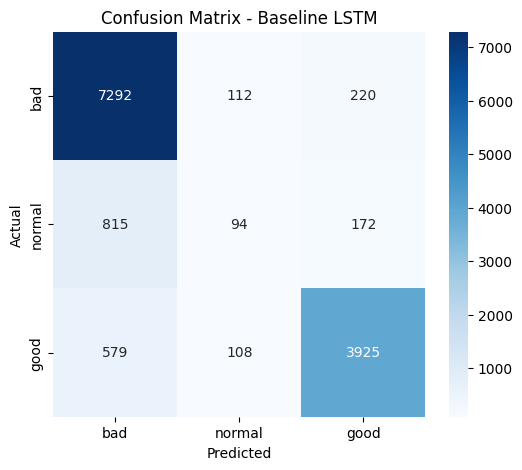

In [201]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_num, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['bad', 'normal', 'good'],
    yticklabels=['bad', 'normal', 'good']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Baseline LSTM')
plt.show()

In [224]:
"""
The baseline LSTM achieved an accuracy of 84.94%,
but its performance is unbalanced across the three classes.
While the model performs well in identifying the "bad" and "good" classes,
the "normal" class suffers from significant misclassification. Out of 1,081 actual "normal" samples,
only 94 were correctly identified, whereas 815 were incorrectly predicted as "bad" and 172 as "good." Consequently,
the recall for the "normal" class is only 9%, and its F1-score is 13%.

"""


'\nThe baseline LSTM achieved an accuracy of 84.94%, \nbut its performance is unbalanced across the three classes.\n While the model performs well in identifying the "bad" and "good" classes, \n the "normal" class suffers from significant misclassification. Out of 1,081 actual "normal" samples,\n  only 94 were correctly identified, whereas 815 were incorrectly predicted as "bad" and 172 as "good." Consequently, \n  the recall for the "normal" class is only 9%, and its F1-score is 13%.\n\n'

In [203]:
# Now it's time for Class Weight.
# Creating Class Weights:

In [204]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Available classes
classes = np.unique(y_train_num)

# Calculating the weight of each class
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_num
)

# Convert to dictionary
class_weights = dict(zip(classes, class_weights_array))

print("Class weights:")
for cls, weight in class_weights.items():
    print(f"Class {cls}: {weight:.4f}")



Class weights:
Class 0: 0.5822
Class 1: 4.1067
Class 2: 0.9625


In [205]:
"""
Why do we do this?

The weighting formula is as follows:

W(i) = N / K * N(i)

where:

(N) = Total number of training samples
(K) = Number of classes
(N(i)) = Number of samples in class (i)

Thus:

High-frequency class → Lower weight

Low-frequency class → Higher weight

Consequently, the weight for the "normal" class will likely be higher than that of the other two classes.

"""


'\nWhy do we do this?\n\nThe weighting formula is as follows:\n\nW(i) = N / K * N(i)\n\nwhere:\n\n(N) = Total number of training samples\n(K) = Number of classes\n(N(i)) = Number of samples in class (i)\n\nThus:\n\nHigh-frequency class → Lower weight\n\nLow-frequency class → Higher weight\n\nConsequently, the weight for the "normal" class will likely be higher than that of the other two classes.\n\n'

In [225]:
# Next step:Using weights during training

# Now, we train the model using the same architecture as before, but with `class_weight`.

In [207]:
history_weighted = model.fit(
    X_train_pad,
    y_train_num,
    validation_data=(X_val_pad, y_val_num),
    epochs=5,
    batch_size=64,
    class_weight=class_weights
)

Epoch 1/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.8095 - loss: 0.5093 - val_accuracy: 0.7541 - val_loss: 0.6181
Epoch 2/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.8380 - loss: 0.4362 - val_accuracy: 0.7376 - val_loss: 0.6467
Epoch 3/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8579 - loss: 0.3840 - val_accuracy: 0.7278 - val_loss: 0.6678
Epoch 4/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8748 - loss: 0.3389 - val_accuracy: 0.7804 - val_loss: 0.6353
Epoch 5/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.8864 - loss: 0.3046 - val_accuracy: 0.7728 - val_loss: 0.6961


In [208]:
# Prediction on test data
y_pred_prob_weighted = model.predict(X_test_pad)

# Converting probabilities to classes
y_pred_num_weighted = np.argmax(y_pred_prob_weighted, axis=1)

print("Shape of probabilities:", y_pred_prob_weighted.shape)
print("First 10 probabilities:")
print(y_pred_prob_weighted[:10])

print("\nFirst 10 predicted classes:")
print(y_pred_num_weighted[:10])

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Shape of probabilities: (13317, 3)
First 10 probabilities:
[[4.5629533e-04 2.6763391e-03 9.9686736e-01]
 [9.9096632e-01 4.8456364e-03 4.1879914e-03]
 [2.9232733e-02 1.8962026e-02 9.5180523e-01]
 [9.9314356e-01 3.6086454e-03 3.2478846e-03]
 [9.9355775e-01 3.3733954e-03 3.0688706e-03]
 [9.9272740e-01 3.6672794e-03 3.6053327e-03]
 [9.9332279e-01 3.5002509e-03 3.1768580e-03]
 [9.5113850e-01 3.1191777e-02 1.7669786e-02]
 [9.9409157e-01 3.0634415e-03 2.8449995e-03]
 [5.2272081e-01 4.2416891e-01 5.3110320e-02]]

First 10 predicted classes:
[2 0 2 0 0 0 0 0 0 0]


In [209]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_num,
    y_pred_num_weighted,
    target_names=["bad", "normal", "good"]
))

              precision    recall  f1-score   support

         bad       0.87      0.81      0.84      7624
      normal       0.20      0.41      0.27      1081
        good       0.92      0.81      0.86      4612

    accuracy                           0.78     13317
   macro avg       0.66      0.67      0.66     13317
weighted avg       0.83      0.78      0.80     13317



In [226]:
"""
The model performs well in identifying the "bad" and "good" classes;
however, the "normal" class remains a primary weakness. While the increase in recall for the "normal" class to 41% indicates improved detection,
the very low precision of 20% reveals that the model frequently misclassifies non-normal samples as "normal." Consequently,
the Macro F1 score of 0.66 indicates that the model's performance across the three classes is not yet balanced.

"""

'\nThe model performs well in identifying the "bad" and "good" classes;\nhowever, the "normal" class remains a primary weakness. While the increase in recall for the "normal" class to 41% indicates improved detection,\nthe very low precision of 20% reveals that the model frequently misclassifies non-normal samples as "normal." Consequently, \nthe Macro F1 score of 0.66 indicates that the model\'s performance across the three classes is not yet balanced.\n\n'

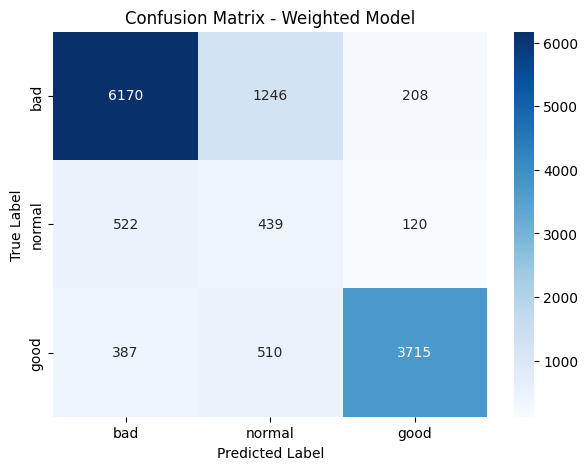

In [211]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_weighted = confusion_matrix(
    y_test_num,
    y_pred_num_weighted
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_weighted,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["bad", "normal", "good"],
    yticklabels=["bad", "normal", "good"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Weighted Model")

plt.show()

In [227]:
"""
Total number of correct predictions (main diagonal) divided by total data: Sum of correct predictions:
 6170 + 439 + 3715 = 10324; Total data: 13317.

The model successfully identified approximately 81% of all actual "bad" cases.

(Of all the cases the model predicted as "bad," 87% were actually "bad.")
Poor performance; the model identified less than half of the actual "normal" data.

(Very low; only 20% of the "normal" predictions were correct.)


"""

'\nTotal number of correct predictions (main diagonal) divided by total data: Sum of correct predictions:\n 6170 + 439 + 3715 = 10324; Total data: 13317.\n\nThe model successfully identified approximately 81% of all actual "bad" cases.\n\n(Of all the cases the model predicted as "bad," 87% were actually "bad.")\nPoor performance; the model identified less than half of the actual "normal" data.\n\n(Very low; only 20% of the "normal" predictions were correct.)\n\n\n'

In [213]:
"""

The class weight has pushed the model too far toward the "normal" class.

In effect, we solved one problem but created a new one:

Our "normal" weight is:

normal = 4.1067

...whereas:

bad  = 0.5822
good = 0.9625

Consequently, when calculating the loss, the model treats an error on the "normal" class as far more costly than an error on the "bad" class.

The model has opted to classify a large number of samples as "normal" to avoid missing any actual "normal" cases.

So, should we abandon class weighting?

Not just yet.

This experiment has yielded a very valuable insight.

We now know that:

Without weighting → "normal" is largely ignored.
With balanced weighting → "normal" is over-predicted.

Therefore, we need to find a middle ground.

That is precisely the next step of the project:

Manually adjusting class weights

Instead of this:

class_weights = {
    0: 0.5822,
    1: 4.1067,
    2: 0.9625
}

We can experiment with some controlled weights.

For instance, the first experiment:

class_weights_tuned = {
    0: 1.0,
    1: 2.0,
    2: 1.0
}

Meaning:

bad     → 1
normal  → 2
good    → 1

This is much more moderate than the weight of 4.1067.

Then, we could run a second experiment, for example:

class_weights_tuned = {
    0: 1.0,
    1: 2.5,
    2: 1.0
}

And, if necessary, compare:

normal = 1.5
normal = 2.0
normal = 2.5
normal = 3.0

"""

'\n\nThe class weight has pushed the model too far toward the "normal" class.\n\nIn effect, we solved one problem but created a new one:\n\nOur "normal" weight is:\n\nnormal = 4.1067\n\n...whereas:\n\nbad  = 0.5822\ngood = 0.9625\n\nConsequently, when calculating the loss, the model treats an error on the "normal" class as far more costly than an error on the "bad" class.\n\nThe model has opted to classify a large number of samples as "normal" to avoid missing any actual "normal" cases.\n\nSo, should we abandon class weighting?\n\nNot just yet.\n\nThis experiment has yielded a very valuable insight.\n\nWe now know that:\n\nWithout weighting → "normal" is largely ignored.\nWith balanced weighting → "normal" is over-predicted.\n\nTherefore, we need to find a middle ground.\n\nThat is precisely the next step of the project:\n\nManually adjusting class weights\n\nInstead of this:\n\nclass_weights = {\n    0: 0.5822,\n    1: 4.1067,\n    2: 0.9625\n}\n\nWe can experiment with some controlle

In [214]:
class_weights_tuned = {
    0: 1.0,   # bad
    1: 2.0,   # normal
    2: 1.0    # good
}

print(class_weights_tuned)

{0: 1.0, 1: 2.0, 2: 1.0}


In [215]:
import tensorflow as tf

# Creating a new model with the same architecture as the original model.
model_tuned = tf.keras.models.clone_model(model)

# Compiling the model
model_tuned.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_tuned.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,611,587 (9.96 MB)

 Trainable params: 2,611,587 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [216]:
history_tuned = model_tuned.fit(
    X_train_pad,
    y_train_num,
    validation_data=(X_val_pad, y_val_num),
    epochs=5,
    batch_size=64,
    class_weight=class_weights_tuned
)

Epoch 1/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.5944 - loss: 1.0507 - val_accuracy: 0.5977 - val_loss: 0.8838
Epoch 2/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.6287 - loss: 1.0091 - val_accuracy: 0.6938 - val_loss: 0.8021
Epoch 3/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - accuracy: 0.7909 - loss: 0.7228 - val_accuracy: 0.8523 - val_loss: 0.4428
Epoch 4/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.8542 - loss: 0.5374 - val_accuracy: 0.8432 - val_loss: 0.4401
Epoch 5/5
971/971 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.8538 - loss: 0.5552 - val_accuracy: 0.8428 - val_loss: 0.4659


In [217]:
y_pred_prob_tuned = model_tuned.predict(X_test_pad)

y_pred_num_tuned = np.argmax(y_pred_prob_tuned, axis=1)

print("Shape of probabilities:", y_pred_prob_tuned.shape)

print("\nFirst 10 probabilities:")
print(y_pred_prob_tuned[:10])

print("\nFirst 10 predicted classes:")
print(y_pred_num_tuned[:10])

417/417 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Shape of probabilities: (13317, 3)

First 10 probabilities:
[[0.00292339 0.02588778 0.9711889 ]
 [0.90454537 0.0855776  0.00987703]
 [0.0624422  0.15244569 0.7851121 ]
 [0.88743705 0.09937766 0.01318521]
 [0.88084054 0.10458352 0.01457602]
 [0.25508872 0.43670556 0.3082057 ]
 [0.90899545 0.08193356 0.00907102]
 [0.8311598  0.14198895 0.02685131]
 [0.90741336 0.08321335 0.00937328]
 [0.79752755 0.16553944 0.03693295]]

First 10 predicted classes:
[2 0 2 0 0 1 0 0 0 0]


In [218]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_num,
    y_pred_num_tuned,
    target_names=["bad", "normal", "good"]
))

              precision    recall  f1-score   support

         bad       0.85      0.94      0.89      7624
      normal       0.27      0.13      0.18      1081
        good       0.91      0.84      0.87      4612

    accuracy                           0.84     13317
   macro avg       0.67      0.64      0.65     13317
weighted avg       0.82      0.84      0.83     13317



In [228]:
"""

The model's main weakness is clearly evident here.

Recall = 13%

Out of 1,081 actual "normal" samples, the model correctly identified only approximately:

 1081 * 0.13 = 140

samples.

This means that about 941 "normal" samples were assigned to other classes.

This figure is highly significant.

Precision = 27%

Of the predictions where the model classified the instance as "normal," only about 27% are actually normal.

Therefore, the model:

misses a large number of actual "normal" instances,
and also makes a significant number of errors when it predicts "normal."
F1 = 0.18
"""

'\n\nThe model\'s main weakness is clearly evident here.\n\nRecall = 13%\n\nOut of 1,081 actual "normal" samples, the model correctly identified only approximately:\n\n$$ 1081 \times 0.13 \x07pprox 140 $$\n\nsamples.\n\nThis means that about 941 "normal" samples were assigned to other classes.\n\nThis figure is highly significant.\n'

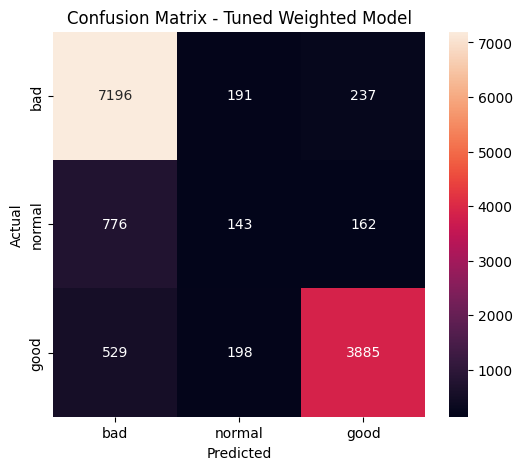

In [220]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_tuned = confusion_matrix(
    y_test_num,
    y_pred_num_tuned
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    xticklabels=["bad", "normal", "good"],
    yticklabels=["bad", "normal", "good"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned Weighted Model")

plt.show()

In [221]:
"""
The overall accuracy of the model has increased from 77.53% in the previous model to 84.28% in the new model, indicating a significant improvement.

'Bad' class:

Recall: 7196 / 7624  = 94.39 (was 80.93% in the previous model);
Precision: 7196 / 8501} = 84.65  (was 87.16% in the previous model).
Analysis: Detection of the 'bad' class has become significantly stronger, and the majority of samples in this class are correctly identified.

'Normal' class:

 Recall:143 / 1081 =  13.23 (40.61% in the previous model);
 Precision: 143 / 532 = 26.88 (20.00% in the previous model).
 Analysis: The recall for the 'normal' class has dropped sharply. The majority of actual instances of this class (776 out of 1,081)
 were incorrectly predicted as 'bad'.

 "Good" class:
  Recall: 3885 / 4612  = 84.24 (80.55% in the previous model);
  Precision: 3885 / 4284 = 90.69 (91.89% in the previous model).
  Analysis: Performance in the "good" class remains very strong and stable, with recall showing a slight improvement.


"""

"\nPerformance analysis by class:\n\n'bad' class (very good performance): Out of 7,624 actual 'bad' samples, 7,163 were correctly identified (approximately 93.9% sensitivity/Recall).\nErrors were minimal (212 cases predicted as 'normal' and 249 as 'good').\n'good' class (good performance): Out of 4,612 actual 'good' samples, 3,960 were correctly identified (approximately 85.8% Recall).\nThe primary error for this class was misclassification as 'bad' (454 cases). 'normal' class (very poor performance):\n Out of 1,081 actual 'normal' samples, only 130 were correctly identified (approximately 12% Recall)! 765 'normal' samples were\nincorrectly predicted as 'bad', and 186 as 'good'.\nThis indicates a strong tendency for the model to classify 'normal' samples as either 'bad' or 'good'.\n"

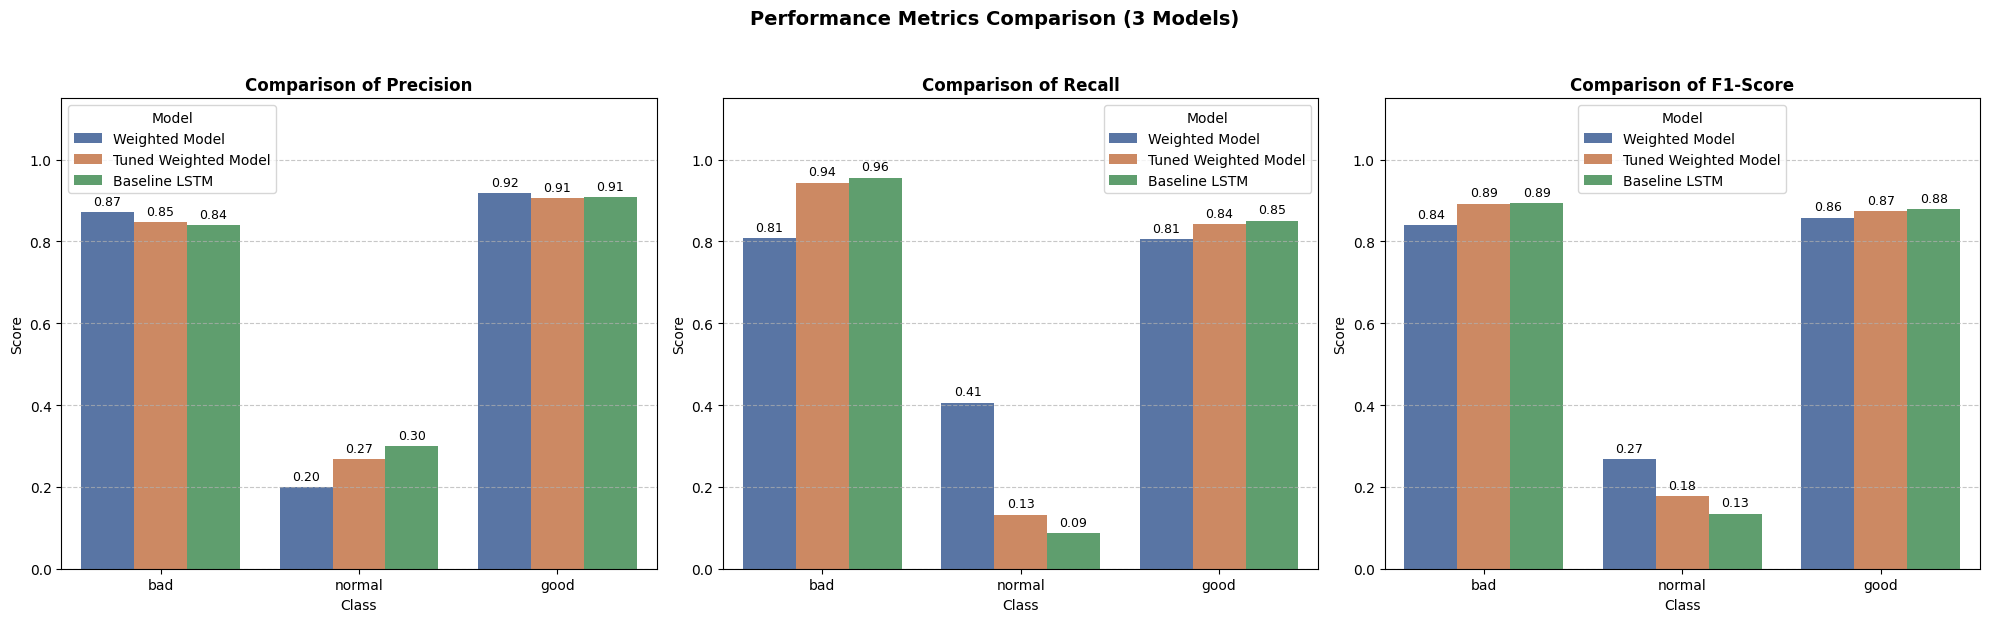

=== Summary Table ===
           Precision                                            Recall  \
Model  Baseline LSTM Tuned Weighted Model Weighted Model Baseline LSTM   
Class                                                                    
bad            0.840                0.846          0.872         0.956   
good           0.909                0.907          0.919         0.851   
normal         0.299                0.269          0.200         0.087   

                                                F1-Score                       \
Model  Tuned Weighted Model Weighted Model Baseline LSTM Tuned Weighted Model   
Class                                                                           
bad                   0.944          0.809         0.894                0.893   
good                  0.842          0.806         0.879                0.873   
normal                0.132          0.406         0.135                0.177   

                       
Model  Weighted Model 

In [236]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Defining initial data from the confusion matrices of 3 modelscm_weighted = np.array([
    [6170, 1246, 208],
    [522,  439,  120],
    [387,  510,  3715]
])

cm_tuned = np.array([
    [7196, 191, 237],
    [776,  143, 162],
    [529,  198, 3885]
])

cm_lstm = np.array([
    [7292, 112, 220],
    [815,  94,  172],
    [579,  108, 3925]
])

labels = ['bad', 'normal', 'good']

# 2. Function to calculate evaluation metrics by classdef calculate_metrics(cm):
    precision, recall, f1 = [], [], []
    for i in range(len(labels)):
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp

        p = tp / (tp + fp) if (tp + fp) > 0 else 0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0
        f = 2 * p * r / (p + r) if (p + r) > 0 else 0

        precision.append(p)
        recall.append(r)
        f1.append(f)
    return precision, recall, f1

prec1, rec1, f1_1 = calculate_metrics(cm_weighted)
prec2, rec2, f1_2 = calculate_metrics(cm_tuned)
prec3, rec3, f1_3 = calculate_metrics(cm_lstm)

# 3. Creating a comprehensive DataFrame of metrics for the 3 modelsdf_metrics = pd.DataFrame({
    'Class': labels * 3,
    'Model': ['Weighted Model']*3 + ['Tuned Weighted Model']*3 + ['Baseline LSTM']*3,
    'Precision': prec1 + prec2 + prec3,
    'Recall': rec1 + rec2 + rec3,
    'F1-Score': f1_1 + f1_2 + f1_3
})

# Converting to 'melted' format for easier plotting with Seaborn
df_melted = pd.melt(df_metrics, id_vars=['Class', 'Model'], var_name='Metric', value_name='Score')

# 4. Plotting comparative graphs
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
metrics = ['Precision', 'Recall', 'F1-Score']
colors = ['#4C72B0', '#DD8452', '#55A868']

for i, metric in enumerate(metrics):
    sns.barplot(
        data=df_melted[df_melted['Metric'] == metric],
        x='Class', y='Score', hue='Model',
        ax=axes[i], palette=colors
    )
    axes[i].set_title(f'Comparison of {metric}', fontsize=12, fontweight='bold')
    axes[i].set_ylim(0, 1.15)
    axes[i].set_ylabel('Score')
    axes[i].set_xlabel('Class')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    # Adding values ​​to the bars
    for p in axes[i].patches:
        h = p.get_height()
        if not np.isnan(h) and h > 0:
            axes[i].annotate(
                f'{h:.2f}',
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 3), textcoords='offset points'
            )

plt.suptitle('Performance Metrics Comparison (3 Models)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 5. Printing the comparative summary table
df_summary = df_metrics.pivot(index='Class', columns='Model', values=['Precision', 'Recall', 'F1-Score'])
print("=== Summary Table ===")
print(df_summary.round(3))

In [233]:
"""
Summary and Model Selection: If the goal is achieving the highest overall accuracy and precisely identifying the primary classes ('bad' and 'good'),
the Baseline LSTM model is the best choice. It achieved the highest rate of correct predictions,
boasting an overall accuracy of 84.94% and the highest F1-scores for both primary classes (0.894 for 'bad' and 0.879 for 'good').
However, if identifying the intermediate class ('normal') is crucial, the Weighted Model offers more balanced performance;
although its overall accuracy is lower (77.52%), it successfully identified the minority 'normal' class at a rate of 40.6%,
whereas the LSTM and Tuned models essentially ignored it. Final Verdict: For general applications where the majority of the data is the priority,
the Baseline LSTM is the winner.

"""